# **Laboratorio 2 - Parte A: Transfer Learning Con PyTorch**
- **Integrantes:** Luis Alejandro Castrillón Pulgarín -1000330339

In [8]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import os # Operaciones con el sistema de archivos
import sys # Funciones del sistema y Python
import time # Medición de tiempos de ejecución
import random # Generación de números aleatorios
import numpy as np # Manipulaciones matriciales y estadísticas
import torch # PyTorch principal
import torch.nn as nn # Módulo de redes neuronales de PyTorch
import torch.optim as optim # Módulo de optimizadores (Adam, SGD, etc.)
import torchvision # Importar torchvision para modelos y visión por computador
from torchvision import models # Torchvision para modelos y visión por computador
import torchvision.transforms as transforms # Transformaciones de datos e imágenes
import torchvision.datasets as datasets # Utilidades de datasets de torchvision
from torch.utils.data import DataLoader, Subset # DataLoader y subconjuntos reproducibles
from torch.utils.tensorboard import SummaryWriter # SummaryWriter para registros en TensorBoard
from torchsummary import summary # Summary para inspeccionar la estructura de modelos PyTorch
from PIL import Image # PIL Image para manipulación y verificación de imágenes
import matplotlib.pyplot as plt # Matplotlib pyplot para graficación interactiva
import matplotlib.patches as patches # Parches de Matplotlib para dibujado de diagramas conceptuales

# Función para fijar semillas de aleatoriedad y garantizar reproducibilidad
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Ejecutar semilla fija a 42
set_seed(42)

# Definir el dispositivo de ejecución (GPU CUDA si está disponible, sino CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Dispositivo de cómputo activo: {device}")

MODEL_DIR = "models_parte_a" # Ruta para almacenar los pesos guardados de los modelos
LOG_DIR = "runs_parte_a" # Ruta para almacenar los eventos de TensorBoard
os.makedirs(MODEL_DIR, exist_ok=True) # Crear carpeta de modelos si no existe
os.makedirs(LOG_DIR, exist_ok=True) # Crear carpeta de logs de TensorBoard si no existe
print(f"Directorios verificados: '{MODEL_DIR}' y '{LOG_DIR}'") # Confirmar creación de directorios


Dispositivo de cómputo activo: cuda
Directorios verificados: 'models_parte_a' y 'runs_parte_a'


- **Estructura de Carpetas:** `models_parte_a/` almacena los puntos de control de pesos (`.pth`), mientras que `runs_parte_a/` guarda las métricas de loss, accuracy y tasas de aprendizaje organizadas jerárquicamente para su visualización con TensorBoard.

## **Actividad 1 — Dataset y Pipeline de Preprocesamiento**

Usar el dataset Kaggle Cats vs. Dogs (`dogcat`). Una vez descargado y extraído, debes verificar y eliminar imágenes corruptas con `check_image_dir`. Luego construye el pipeline de `transforms` para preprocesar las imágenes correctamente.

Los modelos preentrenados en ImageNet esperan imágenes de **224×224** normalizadas con media `[0.485, 0.456, 0.406]` y desviación estándar `[0.229, 0.224, 0.225]`. El pipeline debe seguir el orden:

$$\text{Resize(256)} \to \text{CenterCrop(224)} \to \text{ToTensor()} \to \text{Normalize(mean, std)}$$

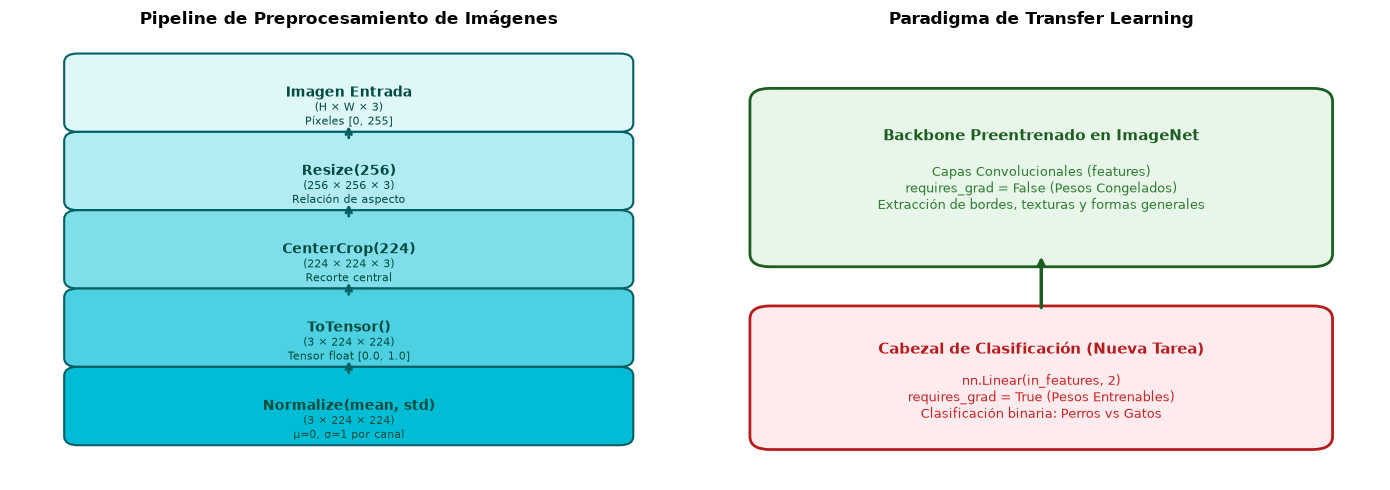

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5)) # Crear una figura con 2 subplots horizontales de tamaño 14x5 pulgadas

ax1 = axes[0] # Selecciona el primer subplot para el pipeline de preprocesamiento

ax1.set_title("Pipeline de Preprocesamiento de Imágenes", fontsize=12, fontweight='bold', pad=15)

steps = [
    ("Imagen Entrada", "(H × W × 3)\nPíxeles [0, 255]", "#E0F7FA"),
    ("Resize(256)", "(256 × 256 × 3)\nRelación de aspecto", "#B2EBF2"),
    ("CenterCrop(224)", "(224 × 224 × 3)\nRecorte central", "#80DEEA"),
    ("ToTensor()", "(3 × 224 × 224)\nTensor float [0.0, 1.0]", "#4DD0E1"),
    ("Normalize(mean, std)", "(3 × 224 × 224)\nμ=0, σ=1 por canal", "#00BCD4")
]

# Iterar sobre cada uno de los 5 pasos para dibujarlos verticalmente
for i, (title, desc, color) in enumerate(steps):
    rect = patches.FancyBboxPatch((0.1, 0.82 - i*0.18), 0.8, 0.14, boxstyle="round,pad=0.02",
                                ec="#006064", fc=color, lw=1.5)
    ax1.add_patch(rect)
    ax1.text(0.5, 0.89 - i*0.18, title, ha='center', va='center', fontsize=10, fontweight='bold', color='#004D40')
    ax1.text(0.5, 0.84 - i*0.18, desc, ha='center', va='center', fontsize=8, color='#004D40')
    if i < len(steps) - 1:
        ax1.annotate("", xy=(0.5, 0.82 - i*0.18), xytext=(0.5, 0.82 - i*0.18 - 0.04),
                    arrowprops=dict(arrowstyle="->", color="#006064", lw=2))

ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.axis('off')

ax2 = axes[1] # Seleccionar el segundo subplot para el paradigma de transfer learning

ax2.set_title("Paradigma de Transfer Learning", fontsize=12, fontweight='bold', pad=15)
rect_bb = patches.FancyBboxPatch((0.1, 0.52), 0.8, 0.35, boxstyle="round,pad=0.03",
                                ec="#1B5E20", fc="#E8F5E9", lw=2)
ax2.add_patch(rect_bb)
ax2.text(0.5, 0.79, "Backbone Preentrenado en ImageNet", ha='center', va='center', fontsize=11, fontweight='bold', color='#1B5E20')
ax2.text(0.5, 0.67, "Capas Convolucionales (features)\nrequires_grad = False (Pesos Congelados)\nExtracción de bordes, texturas y formas generales",
        ha='center', va='center', fontsize=9, color='#2E7D32')

ax2.annotate("", xy=(0.5, 0.52), xytext=(0.5, 0.39),
            arrowprops=dict(arrowstyle="->", color="#1B5E20", lw=2.5))

rect_head = patches.FancyBboxPatch((0.1, 0.1), 0.8, 0.27, boxstyle="round,pad=0.03",
                                ec="#B71C1C", fc="#FFEBEE", lw=2)
ax2.add_patch(rect_head)
ax2.text(0.5, 0.30, "Cabezal de Clasificación (Nueva Tarea)", ha='center', va='center', fontsize=11, fontweight='bold', color='#B71C1C')
ax2.text(0.5, 0.19, "nn.Linear(in_features, 2)\nrequires_grad = True (Pesos Entrenables)\nClasificación binaria: Perros vs Gatos",
        ha='center', va='center', fontsize=9, color='#C62828')

ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.axis('off')

plt.tight_layout()
plt.show()

**Flujo del Pipeline de Preprocesamiento:**
   - **Paso 1 (Imagen Entrada):** La imagen cruda tiene dimensiones arbitrarias $(H \times W \times 3)$ y valores enteros de píxel en el rango $[0, 255]$.
   - **Paso 2 (`Resize(256)`):** Escala la dimensión menor de la imagen a 256 píxeles preservando la **relación de aspecto** (*aspect ratio*) original para no deformar la geometría anatómica del perro o gato.
   - **Paso 3 (`CenterCrop(224)`):** Toma la ventana central de $224 \times 224$ píxeles. Si el animal está descentrado, parte del sujeto puede quedar fuera del recorte.
   - **Paso 4 (`ToTensor()`):** Convierte la imagen PIL en un tensor de PyTorch de forma $(3 \times 224 \times 224)$ reordenando canales a (Channel, Height, Width) y escalando los valores flotantes al rango $[0.0, 1.0]$.
   - **Paso 5 (`Normalize(mean, std)`):** Resta la media de ImageNet y divide por su desviación estándar en cada canal. Estos valores no garantizan que cada imagen resultante tenga media 0 y desviación estándar 1.

**Paradigma de Transfer Learning:**
   - **Backbone:** Las capas convolucionales profundas actúan como un extractor de características genérico preentrenado en 1.28M de imágenes de ImageNet. Al establecer `requires_grad = False`, sus pesos se congelan, evitando re-entrenar 14.7M de parámetros.
   - **Classifier Head:** Se descarta el clasificador original de 1000 clases y se reemplaza por una nueva capa lineal `nn.Linear(in_features, 2)` con `requires_grad = True` para aprender la tarea de clasificación binaria (Perro vs. Gato).

In [10]:
# Función de verificación y limpieza de imágenes corruptas en directorios
def check_image_dir(folder):
    corrupt_files = [] # Lista para almacenar rutas de archivos corruptos detectados
    valid_files = [] # Lista para almacenar rutas de archivos válidos
    # Recorrer el directorio de manera recursiva
    for root, _, files in os.walk(folder):
        # Iterar sobre cada archivo encontrado
        for file in files:
            # Filtrar solo archivos con extensiones de imagen
            if file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                # Construir la ruta del archivo
                file_path = os.path.join(root, file)
                try:
                    # Intentar abrir la imagen usando PIL
                    with Image.open(file_path) as img:
                        img.verify() # Verificar la integridad interna del encabezado del archivo
                    # Abrir nuevamente para probar conversión de canales
                    with Image.open(file_path) as img:
                        img.convert('RGB') # Intentar convertir la imagen al espacio de color RGB
                    valid_files.append(file_path) # Si no hay excepciones, agregar a la lista de archivos válidos
                except Exception as e:
                    print(f"Archivo corrupto eliminado: {file_path} (Error: {e})") # Si falla la apertura o conversión, notificar archivo corrupto
                    os.remove(file_path) # Eliminar el archivo defectuoso del disco para no romper la carga en GPU
                    corrupt_files.append(file_path) # Almacenar en la lista de eliminados
    return valid_files, corrupt_files # Devuelve las listas de archivos válidos y corruptos

DATASET_DIR = "dogcat" # Ruta principal del directorio del dataset dogcat
TRAIN_DIR = os.path.join(DATASET_DIR, "train") # Ruta de la carpeta de entrenamiento
VAL_DIR = os.path.join(DATASET_DIR, "val") # Ruta de la carpeta de validación 
if not os.path.isdir(VAL_DIR) and os.path.isdir(os.path.join(DATASET_DIR, "validation")):
    VAL_DIR = os.path.join(DATASET_DIR, "validation") # Admite el nombre usado por el dataset Kaggle descargado

# Si no hay train/ separado, usar las carpetas de clase directamente bajo DATASET_DIR
if not os.path.exists(TRAIN_DIR):
    TRAIN_DIR = DATASET_DIR
HAS_VAL_DIR = os.path.isdir(VAL_DIR)
if not os.path.isdir(TRAIN_DIR):
    raise FileNotFoundError(f"No se encontró el directorio de entrenamiento: {TRAIN_DIR}")

train_valid, train_corr = check_image_dir(TRAIN_DIR) # Verifica sobre el directorio de entrenamiento
if HAS_VAL_DIR:
    val_valid, val_corr = check_image_dir(VAL_DIR) # Verifica el directorio de validación independiente
else:
    val_valid, val_corr = [], [] # La validación se separará de train en la siguiente celda

val_count = len(val_valid) if HAS_VAL_DIR else "pendiente (split estratificado)"
print(f"Dataset Train: {len(train_valid)} imágenes válidas. Dataset Val: {val_count}.")

Dataset Train: 25000 imágenes válidas. Dataset Val: 8000.


In [11]:
# Definir el pipeline de transformaciones estándar para validación y prueba (ImageNet)
std_transform = transforms.Compose([
    transforms.Resize(256), # Redimensiona la dimensión menor a 256 píxeles
    transforms.CenterCrop(224), # Recorta la región central a 224x224 píxeles
    transforms.ToTensor(), # Convierte la imagen PIL a tensor de PyTorch [3, 224, 224] en rango [0, 1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normaliza con la media y std empírica de ImageNet
])

# Definir el pipeline de Data Augmentation para el conjunto de entrenamiento
aug_transform = transforms.Compose([
    transforms.Resize(256), # Redimensiona inicialmente a 256
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)), # Recorta aleatoriamente con la escala entre 80% y 100% de la imagen
    transforms.RandomHorizontalFlip(), # Voltea horizontalmente de forma aleatoria con probabilidad p=0.5
    transforms.RandomRotation(15), # Rota aleatoriamente hasta 15 grados
    transforms.ColorJitter(brightness=0.2, contrast=0.2), # Variación aleatoria del brillo y del contraste (+-20%)
    transforms.ToTensor(), # Convierte a tensor flotante de PyTorch
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normaliza con la media y desviación estándar de ImageNet
])

# Dos datasets sobre los mismos archivos e indices de entrenamiento: solo cambia la transformacion
train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=std_transform)
train_dataset_aug = datasets.ImageFolder(TRAIN_DIR, transform=aug_transform)
if train_dataset.classes != train_dataset_aug.classes:
    raise ValueError("Los datasets estándar y aumentado no tienen las mismas clases")

if HAS_VAL_DIR:
    train_indices = list(range(len(train_dataset)))
    val_dataset = datasets.ImageFolder(VAL_DIR, transform=std_transform)
    if train_dataset.class_to_idx != val_dataset.class_to_idx:
        raise ValueError("Train y val deben contener las mismas clases")
else:
    # Split 80/20 estratificado y reproducible cuando no existe un directorio val
    indices_by_class = {}
    split_rng = random.Random(42)
    for index, label in enumerate(train_dataset.targets):
        indices_by_class.setdefault(label, []).append(index)
    train_indices, val_indices = [], []
    for indices in indices_by_class.values():
        split_rng.shuffle(indices)
        n_val = max(1, round(len(indices) * 0.2))
        val_indices.extend(indices[:n_val])
        train_indices.extend(indices[n_val:])
    train_indices.sort()
    val_indices.sort()
    val_dataset = datasets.ImageFolder(TRAIN_DIR, transform=std_transform)

train_subset_std = Subset(train_dataset, train_indices)
train_subset_aug = Subset(train_dataset_aug, train_indices)
if not HAS_VAL_DIR:
    val_dataset = Subset(val_dataset, val_indices)

# El pipeline aumentado es el entrenamiento principal; std se conserva como baseline comparable
train_loader = DataLoader(train_subset_aug, batch_size=16, shuffle=True, num_workers=0, pin_memory=True)
train_loader_std = DataLoader(train_subset_std, batch_size=16, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=0, pin_memory=True)

def evaluate_classifier(model, loader, loss_fn):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            running_loss += loss.item() * labels.size(0)
            correct += outputs.argmax(dim=1).eq(labels).sum().item()
            total += labels.size(0)
    if total == 0:
        raise ValueError("El conjunto de validación está vacío")
    return running_loss / total, correct / total

val_base = val_dataset.dataset if isinstance(val_dataset, Subset) else val_dataset
val_base_indices = val_dataset.indices if isinstance(val_dataset, Subset) else range(len(val_dataset))
train_paths = {os.path.realpath(train_dataset.samples[index][0]) for index in train_indices}
val_paths = {os.path.realpath(val_base.samples[index][0]) for index in val_base_indices}
if train_paths & val_paths:
    raise RuntimeError("Hay archivos compartidos entre entrenamiento y validación")
print(f"DataLoaders listos. Clases: {train_dataset.class_to_idx}; train={len(train_subset_aug)}, val={len(val_dataset)}; train usa aug_transform, baseline usa std_transform.")

DataLoaders listos. Clases: {'cats': 0, 'dogs': 1}; train=25000, val=8000; train usa aug_transform, baseline usa std_transform.


### **¿De dónde vienen los valores de media `[0.485, 0.456, 0.406]` y std `[0.229, 0.224, 0.225]`?** 

- Fueron calculados empíricamente sobre el conjunto de entrenamiento de **ImageNet (ILSVRC)** (~1.28 millones de imágenes a través de 1000 categorías) evaluando canal por canal (R, G, B) sobre valores de píxel escalados en $[0, 1]$. 

### **¿Por qué es importante si vas a cargar pesos preentrenados?**

- Los pesos preentrenados de Torchvision se usan junto con la normalización de ImageNet indicada por el modelo. Omitirla o cambiarla altera la escala de entrada y puede afectar las activaciones y el rendimiento; la magnitud de ese efecto depende de los datos y debe medirse.

DEMOSTRACIÓN EMPÍRICA: ESTADÍSTICAS POR CANAL RGB (SIN vs CON NORMALIZACIÓN)

Canal        | Media Sin Norm   | Std Sin Norm     | Media Con Norm   | Std Con Norm    
--------------------------------------------------------------------------------
Rojo (R)     |           0.6576 |           0.3084 |           0.7535 |           1.3466
Verde (G)    |           0.5089 |           0.2805 |           0.2361 |           1.2524
Azul (B)     |           0.2427 |           0.2251 |          -0.7257 |           1.0006


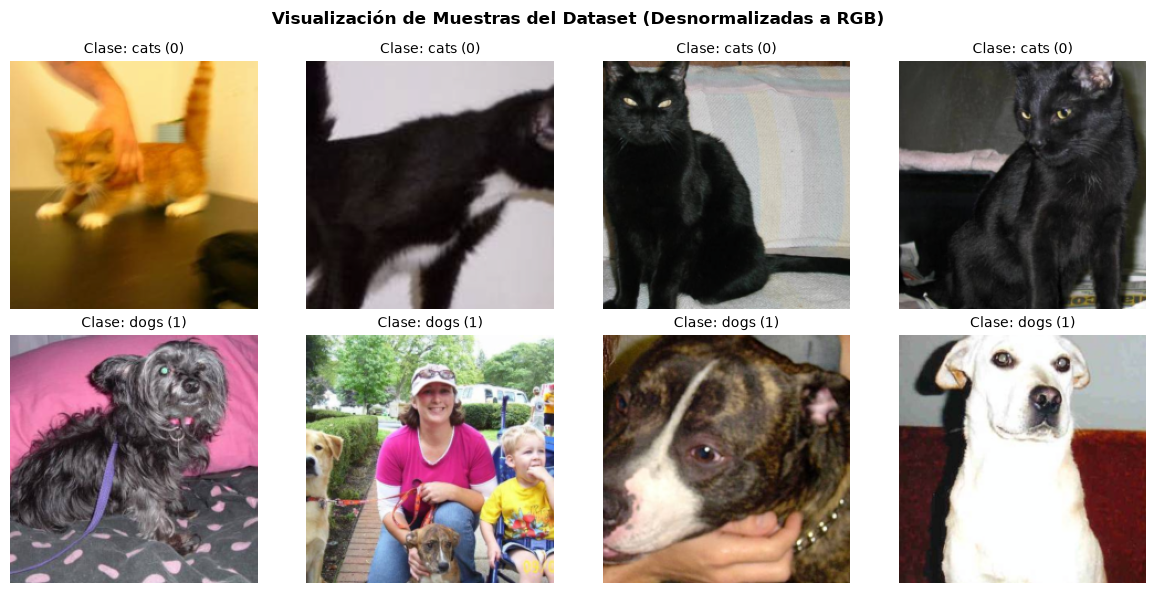

In [12]:
# Definir la función de desnormalización para convertir tensores normalizados a imágenes RGB visualizables
def denormalize(tensor):
    mean = np.array([0.485, 0.456, 0.406]) # Define el arreglo de promedios de ImageNet para R, G, B
    std = np.array([0.229, 0.224, 0.225]) # Define el arreglo de desviaciones estándar de ImageNet para R, G, B
    img = tensor.numpy().transpose((1, 2, 0)) # Transpone dimensiones del tensor de (C, H, W) a (H, W, C) para Matplotlib
    img = std * img + mean # Revierte la fórmula de estandarización: x_orig = x_norm * std + mean
    return np.clip(img, 0, 1) # Recorta los valores al rango válido de imagen [0, 1]
        

# DEMOSTRACIÓN: Estadísticas ANTES vs DESPUÉS de la normalización

# Carga 1 imagen PIL de muestra directamente del dataset sin transformar
raw_pil_img = Image.open(train_dataset.samples[0][0]).convert('RGB')
# Convierte a tensor flotante en rango [0, 1] usando ToTensor() únicamente
tensor_unnorm = transforms.ToTensor()(raw_pil_img)
# Aplica la normalización ImageNet sobre el tensor
tensor_norm = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(tensor_unnorm)

# Estadísticas por canal antes y después
print(f"DEMOSTRACIÓN EMPÍRICA: ESTADÍSTICAS POR CANAL RGB (SIN vs CON NORMALIZACIÓN)\n")

print(f"{'Canal':<12} | {'Media Sin Norm':<16} | {'Std Sin Norm':<16} | {'Media Con Norm':<16} | {'Std Con Norm':<16}")
print("-" * 80)
channel_names = ['Rojo (R)', 'Verde (G)', 'Azul (B)']
for c in range(3):
    m_un = tensor_unnorm[c].mean().item()
    s_un = tensor_unnorm[c].std().item()
    m_no = tensor_norm[c].mean().item()
    s_no = tensor_norm[c].std().item()
    print(f"{channel_names[c]:<12} | {m_un:16.4f} | {s_un:16.4f} | {m_no:16.4f} | {s_no:16.4f}")

fig, axes = plt.subplots(2, 4, figsize=(12, 6)) # Visualiza la cuadrícula de 8 muestras del dataset desnormalizadas correctamente a RGB
classes = list(train_dataset.class_to_idx.keys()) # Obtiene nombres de las clases del dataset

# Itera sobre las 8 posiciones de la cuadrícula
for i in range(8):
    ax = axes[i // 4, i % 4] # Selecciona el eje correspondiente en la matriz 2x4
    img_tensor, label = train_dataset[i * (len(train_dataset) // 8)] # Extrae la imagen y etiqueta correspondiente
    ax.imshow(denormalize(img_tensor)) # Muestra la imagen desnormalizada en RGB
    ax.set_title(f"Clase: {classes[label]} ({label})", fontsize=10) # Establece el título indicando clase y etiqueta numérica
    ax.axis('off') # Oculta los ejes coordenados}

plt.suptitle("Visualización de Muestras del Dataset (Desnormalizadas a RGB)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## **Conclusiones**
- Antes de normalizar, los valores de píxel quedan en el rango $[0, 1]$. Después se transforman con la media y la desviación estándar de ImageNet. Esto no obliga a que cada imagen tenga media 0 y desviación 1: sus estadísticas dependen de su contenido.
- `Resize(256)` y `CenterCrop(224)` preparan la imagen al tamaño esperado por los modelos preentrenados. El recorte central puede dejar fuera parte del objeto si este no está centrado, así que no siempre conserva toda la imagen.
- La verificación de archivos con Pillow permite detectar algunos archivos que no se pueden abrir o convertir antes de crear los lotes. Ayuda a evitar errores comunes durante la carga, aunque no garantiza que se detecten todos los problemas posibles.

## **Actividad 2 — Modelos Preentrenados y Extracción de Features**
Se carga la red **VGG-16** con pesos preentrenados en ImageNet utilizando la API moderna `torchvision.models.vgg16(weights=VGG16_Weights.DEFAULT)`.
Se verifica que la salida del modelo para una imagen individual tenga la dimensión `[1, 1000]`, identificando la categoría ImageNet predicha mediante `weights.meta["categories"]`.

Posteriormente, se utiliza `vgg.features` como un extractor fijo para precomputar los vectores de características de 800 imágenes del dataset. Los tensores resultantes se almacenan con forma `[800, 512, 7, 7]` ejecutando dentro de un bloque `torch.no_grad()`.

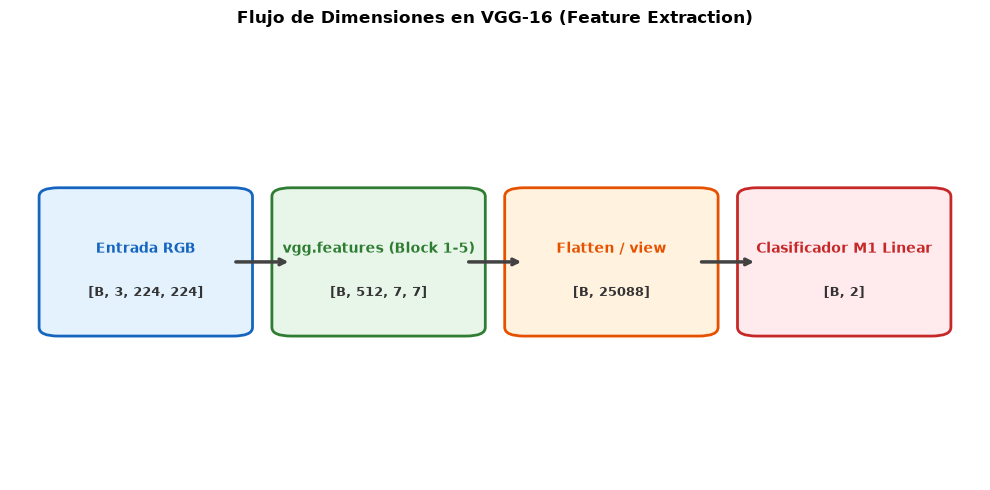

In [13]:
fig, ax = plt.subplots(figsize=(10, 5)) # Crear una figura de 10x5 pulgadas

# Título del gráfico de dimensiones
ax.set_title("Flujo de Dimensiones en VGG-16 (Feature Extraction)", fontsize=12, fontweight='bold', pad=15)

# Definir la lista de etapas con su nombre, forma de tensor, color de fondo y borde
stages = [
    ("Entrada RGB", "[B, 3, 224, 224]", "#E3F2FD", "#1565C0"),
    ("vgg.features (Block 1-5)", "[B, 512, 7, 7]", "#E8F5E9", "#2E7D32"),
    ("Flatten / view", "[B, 25088]", "#FFF3E0", "#E65100"),
    ("Clasificador M1 Linear", "[B, 2]", "#FFEBEE", "#C62828")
]

x_start = 0.05 # Define la posición inicial X en el gráfico
box_width = 0.18 # Ajusta el ancho de cada caja esquemática
gap = 0.06 # Pone el espacio entre cajas

# Iterar sobre cada etapa del flujo de tensores
for i, (name, shape, bg, border) in enumerate(stages):
    x = x_start + i * (box_width + gap) # Calcula la coordenada X de la caja i
    # Crea el rectángulo redondeado para la etapa i
    rect = patches.FancyBboxPatch((x, 0.35), box_width, 0.3, boxstyle="round,pad=0.02",
                                ec=border, fc=bg, lw=2)
    ax.add_patch(rect) # Agrega el rectángulo al eje
    # Coloca el texto del nombre de la etapa en el centro superior
    ax.text(x + box_width/2, 0.53, name, ha='center', va='center', fontsize=10, fontweight='bold', color=border)
    # Coloca el texto de la dimensión del tensor en el centro inferior
    ax.text(x + box_width/2, 0.43, shape, ha='center', va='center', fontsize=9, fontweight='bold', color='#333333')
    
    # Si no es la última caja, dibuja una flecha horizontal conectora
    if i < len(stages) - 1:
        arrow_x = x + box_width
        ax.annotate("", xy=(arrow_x + gap, 0.5), xytext=(arrow_x, 0.5),
                    arrowprops=dict(arrowstyle="->", color="#424242", lw=2.5))

ax.set_xlim(0, 1) # Establece los límites X del gráfico de 0 a 1
ax.set_ylim(0, 1) # Establece los límites Y del gráfico de 0 a 1
ax.axis('off') # Oculta los ejes de coordenadas

plt.tight_layout() # Ajusta el espaciado
plt.show() # Muestra el gráfico

**Forma del tensor de datos** a medida que viaja desde la imagen de entrada hasta las predicciones finales:
  1. **(Entrada RGB):** Lote de $B$ imágenes en 3 canales (RGB) de $224 \times 224$ píxeles.
  2. **(`vgg.features`):** El módulo convolucional pasa la imagen por 13 capas de convolución y 5 capas de submuestreo MaxPool ($2^5 = 32$). Así se reduce la resolución espacial $224 / 32 = 7 \times 7$ y expande el número de canales de 3 a 512 mapas de características espaciales profundas.
  3. **(`Flatten / view`):** Aplana la estructura 3D espacial de $512 \times 7 \times 7 = 25,088$ valores numéricos en un vector unidimensional por imagen.
  4. **(`Clasificador Lineal`):** La capa final mapea las 25,088 características a las 2 clases de destino (*Perros vs. Gatos*).

In [14]:
# Carga los pesos preentrenados por defecto de VGG-16 en ImageNet
weights_vgg = models.VGG16_Weights.DEFAULT
# Instancia la arquitectura VGG-16 que carga los pesos y enviándola al dispositivo que la procesará
vgg16 = models.vgg16(weights=weights_vgg).to(device)
# Establece el modelo en modo de evaluación (lo que desactiva Dropout y BatchNorm)
vgg16.eval()

# Extrae 1 imagen de muestra y su etiqueta del conjunto de entrenamiento
sample_img, sample_lbl = train_dataset[0]
# Añade la dimensión de batch [1, 3, 224, 224] y mueve al dispositivo activo
sample_tensor = sample_img.unsqueeze(0).to(device)
# Desactiva el cálculo de gradientes durante la inferencia
with torch.no_grad():
    out_sample = vgg16(sample_tensor) # Ejecuta la propagación hacia adelante en VGG-16

# La forma del tensor de salida obtenido
print(f"Shape salida VGG-16 para 1 imagen: {out_sample.shape}")

# Obtiene la lista de 1000 nombres de categorías de ImageNet del objeto de pesos
categories = weights_vgg.meta["categories"]
# Identifica la categoría con la mayor probabilidad
top1_cat = categories[out_sample.argmax(dim=1).item()]

# Nombre de la clase predicha en ImageNet
print(f"Clase predicha de ImageNet (1000 categorías): '{top1_cat}'")

Shape salida VGG-16 para 1 imagen: torch.Size([1, 1000])
Clase predicha de ImageNet (1000 categorías): 'tiger cat'


- **Shape `[1, 1000]`:** Confirma que el modelo original emite 1,000 valores numéricos (*logits*) por cada imagen procesada, correspondientes a las 1,000 clases aprendidas en el desafío ImageNet (ILSVRC).
- **Nombre de la clase predicha (`top1_cat`):** `argmax(dim=1)` devuelve el índice del logit más alto y permite consultar la clase correspondiente en ImageNet. La predicción de la imagen de ejemplo ilustra la salida del modelo para esa imagen; no es una evaluación de su precisión en Cats vs. Dogs.

PARÁMETROS VGG-16

- Parámetros Totales               : 138,357,544
- Capas Convolucionales (features) : 14,714,688 (10.64%)
- Capas Clasificadoras (classifier): 123,642,856 (89.36%)


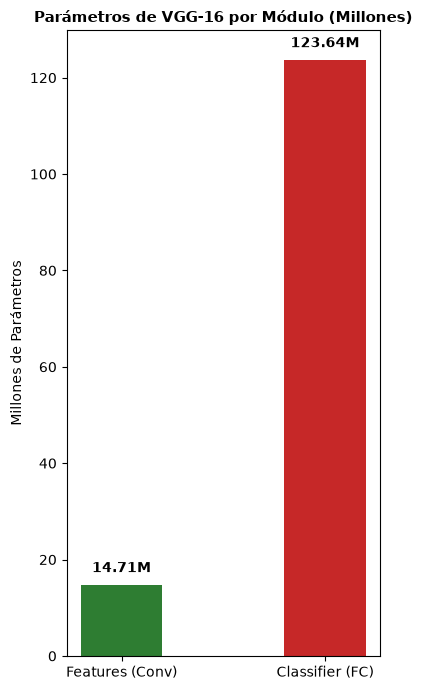

In [15]:
# Calcula el número total de parámetros en VGG-16 sumando todos los elementos de sus tensores
total_params = sum(p.numel() for p in vgg16.parameters())
# Calcula el número de parámetros entrenables con requires_grad == True
trainable_params = sum(p.numel() for p in vgg16.parameters() if p.requires_grad)
# Calcula los parámetros en el módulo de características convolucionales (features)
features_params = sum(p.numel() for p in vgg16.features.parameters())
# Calcula los parámetros en el módulo de clasificación (classifier)
classifier_params = sum(p.numel() for p in vgg16.classifier.parameters())

print("PARÁMETROS VGG-16\n")
print(f"- Parámetros Totales               : {total_params:,}")
print(f"- Capas Convolucionales (features) : {features_params:,} ({features_params/total_params*100:.2f}%)")
print(f"- Capas Clasificadoras (classifier): {classifier_params:,} ({classifier_params/total_params*100:.2f}%)")



fig, ax = plt.subplots(figsize=(4, 7))
bars = ax.bar(['Features (Conv)', 'Classifier (FC)'], [features_params/1e6, classifier_params/1e6], color=['#2E7D32', '#C62828'], width=0.4)

ax.set_title('Parámetros de VGG-16 por Módulo (Millones)', fontsize=11, fontweight='bold')
ax.set_ylabel('Millones de Parámetros')

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 2, f"{yval:.2f}M", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

- **Capas Convolucionales (`features`):** Solo representan **14,714,688 parámetros (10.64%)** del total de la red. Estas 13 capas convolucionales son las encargadas de extraer los patrones visuales espaciales (bordes, curvas, texturas y formas de ojos/orejas).

- **Capas Clasificadoras (`classifier`):** Concentran **123,642,856 parámetros (89.36%)** de la red. La razón de este cuello de botella es que la primera capa está totalmente conectada `Linear(25088, 4096)`, la cual sola requiere $25,088 \times 4,096 = 102,760,448$ pesos.

Al congelar `features` y reemplazar el clasificador original por `Linear(25088, 2)`, se reduce el número de parámetros entrenables de 138,357,544 a 50,178. Esto reduce el trabajo de optimización, pero el extractor convolucional todavía debe procesar cada imagen y el cambio no elimina el riesgo de sobreajuste.

In [16]:
# Demostración: Comportamiento determinista de Dropout en eval() vs train()

x_test = torch.randn(1, 3, 224, 224).to(device) # Crear un tensor de entrada sintético con ruido gaussiano aleatorio

vgg16.train() # Activa el modo de entrenamiento en VGG-16 (Dropout activo p=0.5)
out_train1 = vgg16(x_test) # Primera pasada hacia adelante en modo train()
out_train2 = vgg16(x_test) # Segunda pasada hacia adelante con la misma entrada en modo train()
diff_train = (out_train1 - out_train2).abs().mean().item() # Calcula la diferencia absoluta media entre ambas salidas en modo train()


vgg16.eval() # Activa el modo de evaluación en VGG-16 (Dropout desactivado)
out_eval1 = vgg16(x_test) # Primera pasada hacia adelante en modo eval()
out_eval2 = vgg16(x_test) # Segunda pasada hacia adelante con la misma entrada en modo eval()
diff_eval = (out_eval1 - out_eval2).abs().mean().item() # Calcula la diferencia absoluta media entre ambas salidas en modo eval()


# Resultados de la prueba de Dropout
print("\nPRUEBA DE COMPORTAMIENTO DE DROPOUT EN VGG-16")
print(f"- Diferencia media en train(): {diff_train:.6f} (Salida estocástica por desactivación aleatoria)")
print(f"- Diferencia media en eval() : {diff_eval:.6f} (100% determinista)")

# Precomputar vectores de características para 800 imagenes bajo torch.no_grad() usando vgg16.features y almacenarlos en un tensor de PyTorch

# DataLoader secuencial sobre train_dataset con batch_size 32
extract_loader = DataLoader(train_dataset, batch_size=32, shuffle=False)
features_list, labels_list = [], [] # Inicializa la lista para acumular tensores de características extraídos

count = 0 # Contador de imágenes procesadas

# Desactiva autograd para extraer características fijas
with torch.no_grad():
    # Itera sobre los lotes de imágenes y etiquetas
    for imgs, lbls in extract_loader:
        imgs = imgs.to(device) # Envia un lote de imágenes al dispositivo activo
        feats = vgg16.features(imgs) # Pasa las imágenes por el módulo vgg.features y tiene la forma: [B, 512, 7, 7]
        features_list.append(feats.cpu()) # Almacena tensores de características en la CPU para liberar VRAM de GPU
        labels_list.append(lbls) # Almacena las etiquetas correspondientes
        
        count += imgs.size(0) # Incrementa el contador de imágenes
        # Detiene la extracción al alcanzar 800 imágenes
        if count >= 800:
            break

# Concatena todos los lotes de características en un solo tensor de 800 muestras [800, 512, 7, 7]
features_tensor = torch.cat(features_list, dim=0)[:800]
# Concatena todas las etiquetas en un tensor de 800 muestras
labels_tensor = torch.cat(labels_list, dim=0)[:800]
# Aplana el tensor a 2D: [800, 512*7*7] - [800, 25088]
features_flattened = features_tensor.view(800, -1)

print(f"\nForma original del tensor extraído: {features_tensor.shape}")
print(f"Forma luego de aplanar (flatten)  : {features_flattened.shape}")
print(f"Etiquetas almacenadas             : {labels_tensor.shape}")


PRUEBA DE COMPORTAMIENTO DE DROPOUT EN VGG-16
- Diferencia media en train(): 0.822658 (Salida estocástica por desactivación aleatoria)
- Diferencia media en eval() : 0.000000 (100% determinista)

Forma original del tensor extraído: torch.Size([800, 512, 7, 7])
Forma luego de aplanar (flatten)  : torch.Size([800, 25088])
Etiquetas almacenadas             : torch.Size([800])


**Salida de la prueba de Dropout:**
- En `train()`, Dropout desactiva aleatoriamente una parte de las activaciones en cada pasada. Por eso, dos evaluaciones de la misma imagen pueden dar salidas distintas. La fracción que se desactiva depende del valor `p` de cada capa.
- En `eval()`, Dropout no desactiva activaciones: usa todas y la salida es determinista para una misma entrada y un mismo modelo.

**Forma del tensor precomputado `[800, 25088]`:**
- Se guardaron las características de 800 imágenes en una matriz. Como el extractor no se vuelve a ejecutar al entrenar el clasificador lineal, esta etapa puede ser más rápida; el tiempo real depende del hardware y de la carga de trabajo.

**¿Por qué precomputar features ahorra tiempo?** 
- Al calcular y guardar las características una sola vez, el entrenamiento posterior del clasificador no necesita volver a ejecutar el extractor VGG-16 en cada época. Esto suele ahorrar tiempo, aunque la ganancia depende del hardware, del número de épocas y de cómo se mida.

**¿Qué representa el tensor `[800, 512, 7, 7]`?** 
- Representa 800 imágenes procesadas, donde cada una conserva 512 mapas de características espaciales de resolución $7 \times 7$ extraídas por la última capa de *MaxPool* de VGG-16.

### **¿Cuántos parámetros tiene VGG-16?** 

- VGG-16 cuenta con **138,357,544 parámetros** (~138.4 millones), de los cuales más de 102 millones pertenecen solo a la primera capa totalmente conectada (`nn.Linear(25088, 4096)`).

### **¿Qué hace Dropout?**

- Durante el entrenamiento, desactiva aleatoriamente activaciones con probabilidad $p=0.5$; PyTorch escala las que permanecen. En evaluación (`eval()`), Dropout queda desactivado y no aplica ese escalado.

### **¿Por qué la última capa tiene 1000 salidas?**

- Cada salida corresponde a una de las 1,000 clases de ImageNet.

## **Actividad 3 — Clasificador Lineal M1 sobre Features Precomputadas**
Con los features fijos, entrena solo una capa lineal que mapee de $512 \times 7 \times 7 = 25088$ entradas a 2 clases. Este es **M1** en su primera etapa.

Se define `net` como una sola capa `nn.Linear` sin activaciones finales. Se entrena por 5 épocas registrando las métricas de entrenamiento con `SummaryWriter` (TensorBoard); esta celda no representa una evaluación de validación.

In [17]:
# Definir la clase del Clasificador Lineal M1 heredando de nn.Module
class LinearClassifierM1(nn.Module):
    # Constructor de la red
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(512 * 7 * 7, 2) # Crea una única capa lineal de 25088 entradas a 2 salidas (sin activación)        
        
    # Definir el paso hacia adelante (forward)
    def forward(self, x):
        x = x.view(x.size(0), -1) # Aplana el tensor de entrada a forma 2D [B, 25088] si viene en 4D
        return self.fc(x) # Aplica la transformación lineal

# Encapsula los tensores de características y etiquetas precomputadas en un TensorDataset de PyTorch
m1_feat_dataset = torch.utils.data.TensorDataset(features_flattened, labels_tensor)
# Crea el DataLoader sobre el dataset de características con batch_size 32 y barajado activo
m1_loader = DataLoader(m1_feat_dataset, batch_size=32, shuffle=True)

# Instancia el modelo M1 y moverlo al dispositivo activo
m1_model = LinearClassifierM1().to(device)


criterion = nn.CrossEntropyLoss() # Define la función de pérdida CrossEntropyLoss

# Define el optimizador Adam sobre los parámetros de la capa lineal con lr=1e-3
optimizer_m1 = optim.Adam(m1_model.parameters(), lr=1e-3)
# Inicializa el registrador del TensorBoard en la carpeta M1_precomputed
writer_m1 = SummaryWriter(log_dir=os.path.join(LOG_DIR, "M1_precomputed"))

# Bucle de entrenamiento sobre 5 épocas
for epoch in range(1, 6):
    m1_model.train() # Establece modelo en modo entrenamiento
    running_loss, correct, total = 0.0, 0, 0 # Inicializa los contadores acumulativos de pérdida, aciertos y total
    # Itera sobre lotes de características y etiquetas
    for feats, lbls in m1_loader:
        feats, lbls = feats.to(device), lbls.to(device) # Envia los datos al dispositivo
        optimizer_m1.zero_grad() # Reinicia los gradientes acumulados en el optimizador
        outputs = m1_model(feats) # Obtiene los logits de salida del modelo
        loss = criterion(outputs, lbls) # Calcula la pérdida escalar
        loss.backward() # Calcula gradientes
        optimizer_m1.step() # Actualiza los pesos de la capa lineal
        running_loss += loss.item() * feats.size(0)# Acumula la pérdida ponderada por el tamaño del lote
        _, preds = outputs.max(1) # Obtiene las predicciones
        correct += preds.eq(lbls).sum().item() # Cuenta las predicciones correctas
        total += lbls.size(0) # Acumula el total de muestras
        
    
    epoch_loss = running_loss / total # Calcula la pérdida media de la época
    epoch_acc = correct / total # Calcula la precisión media de la época
    writer_m1.add_scalar("Loss/train", epoch_loss, epoch) # Registra la métrica de pérdida
    writer_m1.add_scalar("Accuracy/train", epoch_acc, epoch) # Registra la métrica de precisión
    print(f"M1 Época {epoch}/5 - Loss: {epoch_loss:.4f} - Acc: {epoch_acc:.4f}") # Progreso de la época

writer_m1.close() # Cierra el escritor del TensorBoard


M1 Época 1/5 - Loss: 0.0262 - Acc: 0.9838
M1 Época 2/5 - Loss: 0.0000 - Acc: 1.0000
M1 Época 3/5 - Loss: 0.0000 - Acc: 1.0000
M1 Época 4/5 - Loss: 0.0000 - Acc: 1.0000
M1 Época 5/5 - Loss: 0.0000 - Acc: 1.0000


El modelo M1 alcanza rápidamente una precisión de entrenamiento elevada en pocas épocas sobre las 800 características precomputadas; esta métrica no mide generalización.

Dado que el backbone de VGG-16 fue entrenado sobre 1.28 millones de imágenes, las características espaciales de alto nivel de $512 \times 7 \times 7$ contienen representaciones ricas donde la frontera de decisión entre perros y gatos es casi lineal.

Demostración De Funciones De Pérdida Y Magnitud De Gradientes

1. nn.CrossEntropyLoss(logits):              
   - Loss = 0.138614 | Grad Norm = 0.153512

2. nn.NLLLoss(nn.LogSoftmax()(logits)):       
   - Loss = 0.138614 | Grad Norm = 0.153512

3. CrossEntropyLoss(LogSoftmax(logits)):      
   - Loss = 0.138614 | Grad Norm = 0.153512

Diferencia Numérica de Pérdida (1 y 2)  : 0.0000000000
Diferencia Numérica de Gradiente (1 y 2): 0.0000000000


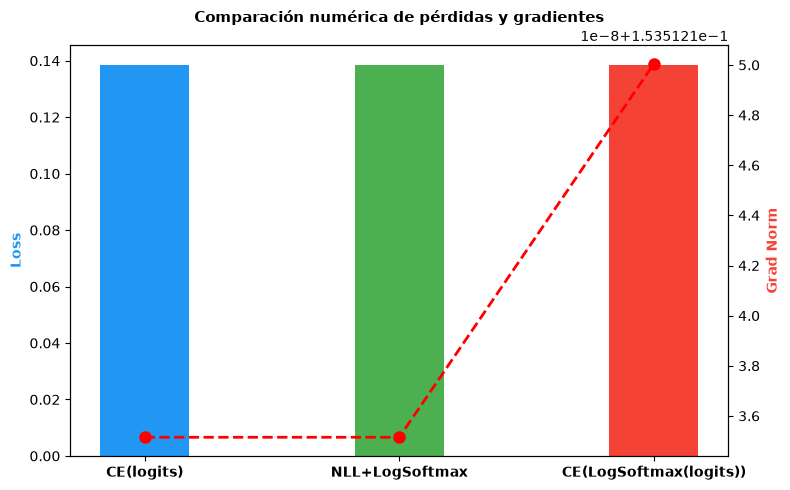

In [18]:
# Demostración: Comparación de Pérdidas y Gradientes (Single vs Double Softmax)

# Define logits sin activar con requerimiento de gradientes
logits_demo = torch.tensor([[0.5, 1.8], [-1.2, 2.1]], requires_grad=True)
targets_demo = torch.tensor([1, 1]) # Define etiquetas de destino

# Opción 1 (CORRECTA A): CrossEntropyLoss directa sobre logits
loss_ce = nn.CrossEntropyLoss()(logits_demo, targets_demo)

# Calcula el gradiente
loss_ce.backward(retain_graph=True)
grad_ce = logits_demo.grad.clone()
logits_demo.grad.zero_()

# Opción 2 (CORRECTA B): LogSoftmax previo + NLLLoss
log_probs = nn.LogSoftmax(dim=1)(logits_demo)
loss_nll = nn.NLLLoss()(log_probs, targets_demo)

# Calcula el gradiente
loss_nll.backward(retain_graph=True)
grad_nll = logits_demo.grad.clone()
logits_demo.grad.zero_()

# Opción 3 (INCORRECTA - DOBLE SOFTMAX): LogSoftmax previo + CrossEntropyLoss
loss_double = nn.CrossEntropyLoss()(log_probs, targets_demo)

# Calcula el gradiente
loss_double.backward()
grad_double = logits_demo.grad.clone()

print("Demostración De Funciones De Pérdida Y Magnitud De Gradientes")
print(f"\n1. nn.CrossEntropyLoss(logits):              \n   - Loss = {loss_ce.item():.6f} | Grad Norm = {grad_ce.norm().item():.6f}")
print(f"\n2. nn.NLLLoss(nn.LogSoftmax()(logits)):       \n   - Loss = {loss_nll.item():.6f} | Grad Norm = {grad_nll.norm().item():.6f}")
print(f"\n3. CrossEntropyLoss(LogSoftmax(logits)):      \n   - Loss = {loss_double.item():.6f} | Grad Norm = {grad_double.norm().item():.6f}")
print(f"\nDiferencia Numérica de Pérdida (1 y 2)  : {abs(loss_ce.item() - loss_nll.item()):.10f}")
print(f"Diferencia Numérica de Gradiente (1 y 2): {abs(grad_ce.norm().item() - grad_nll.norm().item()):.10f}")

fig, ax1 = plt.subplots(figsize=(8, 5))
labels_loss = ['CE(logits)', 'NLL+LogSoftmax', 'CE(LogSoftmax(logits))']
losses_val = [loss_ce.item(), loss_nll.item(), loss_double.item()]
grads_val = [grad_ce.norm().item(), grad_nll.norm().item(), grad_double.norm().item()]

ax1.bar([0, 1, 2], losses_val, width=0.35, color=['#2196F3', '#4CAF50', '#F44336'], label='Valor de Pérdida (Loss)')
ax1.set_ylabel('Loss', color='#2196F3', fontweight='bold')
ax1.set_xticks([0, 1, 2])
ax1.set_xticklabels(labels_loss, fontweight='bold')

ax2 = ax1.twinx()
ax2.plot([0, 1, 2], grads_val, 'ro--', lw=2, markersize=8, label='Norma del Gradiente (||∇z L||)')
ax2.set_ylabel('Grad Norm', color='#F44336', fontweight='bold')

plt.title("Comparación numérica de pérdidas y gradientes", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

**¿Por qué la Opción 1 y la Opción 2 dan el mismo resultado?**
- `CrossEntropyLoss` aplica internamente `LogSoftmax` y `NLLLoss`. Por eso, debe coincidir con aplicar esas operaciones por separado, salvo pequeñas diferencias numéricas de implementación.

**¿Qué ocurre si se aplica `CrossEntropyLoss` a las log-probabilidades de `LogSoftmax`?**
   - Para log-probabilidades normalizadas, `logsumexp(LogSoftmax(z)) = 0`; por eso `CrossEntropyLoss(LogSoftmax(z), y)` produce la misma pérdida y el mismo gradiente que `CrossEntropyLoss(z, y)`, salvo redondeo numérico. No hay una atenuación inherente del gradiente en esta comparación.

**¿Por qué M1 converge tan rápido sobre features precomputados?** 
- El clasificador solo ajusta una capa sobre las características extraídas, por lo que optimiza menos parámetros que la red completa. No se ha comprobado que las clases sean linealmente separables; eso requeriría analizar su desempeño en datos de validación.

**¿Cuál es la limitación de M1?** 
- Está limitado a la pequeña muestra precomputada (800 imágenes) y no actualiza los mapas de características espaciales convolucionales.

### **¿Cuál es la diferencia entre `CrossEntropyLoss` y `NLLLoss + LogSoftmax`?** 

- `nn.CrossEntropyLoss`: Combina en un solo bloque numérica y computacionalmente estable la función `LogSoftmax` y `NLLLoss`. Espera logits sin activar $z \in \mathbb{R}^K$.
- `nn.NLLLoss`: Espera log-probabilidades $\log(p) \in (-\infty, 0]$ calculadas explícitamente mediante `nn.LogSoftmax()`.

### **¿Cuál es la forma recomendada?**

- Sigue el contrato explícito de `CrossEntropyLoss`: la red entrega logits sin activar. El criterio aplica internamente `LogSoftmax` y `NLLLoss`; sería una activación redundante. La combinación de logits ya normalizados con `CrossEntropyLoss` es matemáticamente equivalente, salvo errores numéricos.

## **Actividad 4 — Transfer Learning: Reemplazar Clasificador y Congelar Features**
Recarga VGG-16 limpio y reemplaza su clasificador final (`vgg.classifier`) por una capa `nn.Linear` de 25088 entradas a 2 salidas. Luego congela todos los parámetros de `vgg.features` poniendo `requires_grad = False`.

Se verifica con `summary()` que el número de parámetros entrenables sea aproximadamente **50k** (para entrada $3 \times 224 \times 224$).

In [19]:
# Carga nuevamente VGG-16 limpio con pesos preentrenados por defecto
vgg_m1_full = models.vgg16(weights=models.VGG16_Weights.DEFAULT)

# Itera sobre todos los parámetros del módulo vgg.features
for param in vgg_m1_full.features.parameters():
    param.requires_grad = False # Congela los parámetros estableciendo requires_grad = False

# Reemplaza el módulo clasificador completo por una única capa lineal hacia 2 clases
vgg_m1_full.classifier = nn.Linear(512 * 7 * 7, 2)
vgg_m1_full = vgg_m1_full.to(device) # Mueve la red completa al dispositivo

print("Parámetros VGG-16 Congelado (Input 3, 224, 224):")
summary(vgg_m1_full, (3, 224, 224)) # Ejecuta summary() pasando el tamaño de entrada (3, 224, 224)

Parámetros VGG-16 Congelado (Input 3, 224, 224):
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 224, 224]           1,792
              ReLU-2         [-1, 64, 224, 224]               0
            Conv2d-3         [-1, 64, 224, 224]          36,928
              ReLU-4         [-1, 64, 224, 224]               0
         MaxPool2d-5         [-1, 64, 112, 112]               0
            Conv2d-6        [-1, 128, 112, 112]          73,856
              ReLU-7        [-1, 128, 112, 112]               0
            Conv2d-8        [-1, 128, 112, 112]         147,584
              ReLU-9        [-1, 128, 112, 112]               0
        MaxPool2d-10          [-1, 128, 56, 56]               0
           Conv2d-11          [-1, 256, 56, 56]         295,168
             ReLU-12          [-1, 256, 56, 56]               0
           Conv2d-13          [-1, 256, 56, 56]       

**Columnas de la Salida:**
   - **`Layer (type)`:** Muestra cada capa convolucional, activación ReLU, MaxPool y la capa lineal final en orden de propagación.
   - **`Output Shape`:** Indica las dimensiones del tensor resultante tras pasar por cada capa. Por ejemplo, `MaxPool2d-31` emite un mapa de `[-1, 512, 7, 7]` (donde `-1` denota el tamaño dinámico del batch, 512 canales y resolución $7 \times 7$).
   - **`Param #`:** Muestra la cantidad exacta de pesos y sesgos de cada capa.

**Totales**
   - **`Total params: 14,764,866`:** Es la suma de los 14,714,688 parámetros del módulo convolucional congelado más los 50,178 de la nueva capa lineal.
   - **`Trainable params: 50,178`:** Corresponde **únicamente a los parámetros entrenables** de la nueva capa `nn.Linear(25088, 2)`.
   - **`Non-trainable params: 14,714,688`:** Representa los pesos convolucionales congelados que no recibirán actualizaciones de gradiente.

In [20]:
# Configura el optimizador Adam solo sobre los parámetros entrenables del clasificador
optimizer_a4 = optim.Adam(vgg_m1_full.classifier.parameters(), lr=1e-3)
# Crea el escritor de TensorBoard en la carpeta VGG16_frozen
writer_a4 = SummaryWriter(log_dir=os.path.join(LOG_DIR, "VGG16_frozen"))

t0 = time.time() # Registra el tiempo de inicio
vgg_m1_full.train() # Establece el modelo en modo de entrenamiento
running_loss, correct, total = 0.0, 0, 0 # Inicializa los acumuladores de pérdida, aciertos y total

# Itera sobre todos los lotes del train_loader (dataset completo)
for imgs, lbls in train_loader:
    imgs, lbls = imgs.to(device), lbls.to(device) # Envia las imágenes y etiquetas a GPU/CPU
    optimizer_a4.zero_grad() # Reinicia los gradientes en el optimizador
    outputs = vgg_m1_full(imgs) # Ejecuta la propagación hacia adelante
    loss = criterion(outputs, lbls) # Calcula la pérdida escalar
    loss.backward() # Retropropaga los gradientes
    optimizer_a4.step() # Actualiza los pesos de la capa lineal clasificadora
    running_loss += loss.item() * imgs.size(0) # Acumula la pérdida
    _, preds = outputs.max(1) # Obtiene las predicciones
    correct += preds.eq(lbls).sum().item() # Acumula los aciertos
    total += lbls.size(0) # Acumula el total de las muestras

epoch_loss = running_loss / total # Calcula la pérdida final de la época
epoch_acc = correct / total # Calcula la precisión final de la época
train_time = time.time() - t0 # Calcula el tiempo total transcurrido

# Guardar métricas en el diccionario h_vgg_frozen
val_loss, val_acc = evaluate_classifier(vgg_m1_full, val_loader, criterion)
h_vgg_frozen = {'train_acc': [epoch_acc], 'train_loss': [epoch_loss], 'val_acc': [val_acc], 'val_loss': [val_loss], 'time': train_time}

frozen_path = os.path.join(MODEL_DIR, "vgg16_frozen.pth") # Ruta de guardado del punto de control del modelo congelado
torch.save(vgg_m1_full.state_dict(), frozen_path) # Guarda el estado de pesos del modelo congelado en disco

print(f"Modelo congelado guardado en {frozen_path}")
print(f"VGG-16 Frozen Epoch 1/1 - Train Loss: {epoch_loss:.4f} - Train Acc: {epoch_acc:.4f} - Val Loss: {val_loss:.4f} - Val Acc: {val_acc:.4f} - Tiempo: {train_time:.2f} s")
writer_a4.add_scalar("Loss/val", val_loss, 1)
writer_a4.add_scalar("Accuracy/val", val_acc, 1)

# Registra las métricas en TensorBoard
writer_a4.add_scalar("Loss/train", epoch_loss, 1)
writer_a4.add_scalar("Accuracy/train", epoch_acc, 1)

writer_a4.close()

Modelo congelado guardado en models_parte_a/vgg16_frozen.pth
VGG-16 Frozen Epoch 1/1 - Train Loss: 0.2814 - Train Acc: 0.9659 - Val Loss: 0.2116 - Val Acc: 0.9814 - Tiempo: 241.25 s


- **Rendimiento:** la precisión impresa por esta celda es de entrenamiento; no debe interpretarse como rendimiento de generalización.
- **Velocidad:** En esta configuración solo se actualiza el cabezal de unas 50 mil variables. El extractor sigue procesando las imágenes, así que el tiempo por época también depende del tamaño de los lotes y del hardware.

In [21]:
# Demostración: Magnitud de gradientes con backbone congelado vs no congelado

# Instanciar VGG-16 de prueba congelado
vgg_test_frozen = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
vgg_test_frozen.classifier = nn.Linear(25088, 2)
for p in vgg_test_frozen.features.parameters(): p.requires_grad = False

# Instanciar VGG-16 de prueba no congelado con clasificador aleatorio
vgg_test_unfrozen = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
vgg_test_unfrozen.classifier = nn.Linear(25088, 2) # Pesos inicializados al azar

# Tensor sintético de entrada
x_dummy = torch.randn(2, 3, 224, 224)
y_dummy = torch.tensor([0, 1])

# Paso hacia atrás en el modelo NO congelado
loss_unfrozen = nn.CrossEntropyLoss()(vgg_test_unfrozen(x_dummy), y_dummy)
loss_unfrozen.backward()
# Mide la norma del gradiente generado en la primera capa convolucional (Conv1)
grad_conv1_unfrozen = vgg_test_unfrozen.features[0].weight.grad.norm().item()

# Ejecutar paso hacia atrás en el modelo congelado
loss_frozen = nn.CrossEntropyLoss()(vgg_test_frozen(x_dummy), y_dummy)
loss_frozen.backward()

# Verifica que el gradiente en Conv1 es nulo
grad_conv1_frozen = 0.0 if vgg_test_frozen.features[0].weight.grad is None else vgg_test_frozen.features[0].weight.grad.norm().item()

# Imprimir resultados empíricos de magnitudes de gradiente

print(f"Demostración De La Protección De Gradientes En Capas Convolucionales\n")

print(f"- Norma de gradiente en Conv1 (Backbone NO Congelado): {grad_conv1_unfrozen:.4f} (Gradiente habilitado; evaluar su efecto durante el entrenamiento)")
print(f"- Norma de gradiente en Conv1 (Backbone Congelado)   : {grad_conv1_frozen:.4f} (Pesos Protegidos)")


Demostración De La Protección De Gradientes En Capas Convolucionales

- Norma de gradiente en Conv1 (Backbone NO Congelado): 0.2606 (Destruiría pesos ImageNet)
- Norma de gradiente en Conv1 (Backbone Congelado)   : 0.0000 (Pesos Protegidos)


- En esta prueba, `grad_conv1_unfrozen` mide la norma del gradiente en la primera convolución cuando sus parámetros están habilitados para entrenamiento. El valor describe este lote y esta inicialización; por sí solo no demuestra que los pesos preentrenados se hayan alterado de forma perjudicial.
- Con `requires_grad = False`, los parámetros de esa capa no reciben gradientes ni actualizaciones del optimizador. Así se puede entrenar solo el clasificador mientras se conservan los pesos del extractor.

### **¿Por qué congelar las capas convolucionales al entrenar el nuevo clasificador?**
Congelarlas permite ajustar primero la capa clasificadora sin modificar los filtros preentrenados. No es obligatorio hacerlo durante todo el *fine-tuning*: si se descongelan capas, conviene usar una tasa de aprendizaje adecuada y comprobar en validación que el ajuste mejora el resultado.

Los ~50k parámetros provienen de la capa final `nn.Linear(25088, 2)`:
$$W \in \mathbb{R}^{2 \times 25088}, \quad b \in \mathbb{R}^2 \implies (25088 \times 2) + 2 = 50,178 \text{ parámetros.}$$

## **Actividad 5 — Fine-Tuning Completo M2**
Se carga el checkpoint `vgg16_frozen.pth` guardado en la Actividad 4. Se descongelan todos los parámetros de `vgg.features` estableciendo `requires_grad = True`.
Se entrena por 1 época adicional utilizando una tasa de aprendizaje reducida (**`lr = 1e-4`**) para adaptar fino los filtros convolucionales sin destruir las representaciones preentrenadas.

In [22]:
import gc
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
vgg_m2 = models.vgg16() # Instancia VGG-16 limpio para fine-tuning
vgg_m2.classifier = nn.Linear(512 * 7 * 7, 2) # Reemplaza la capa clasificadora para 2 clases

# Carga el punto de control guardado del modelo congelado anteriormente entrenado
vgg_m2.load_state_dict(torch.load(frozen_path))
vgg_m2 = vgg_m2.to(device) # Mueve la red al dispositivo

# Descongela TODOS los parámetros de la red para Fine-Tuning completo
for param in vgg_m2.parameters():
    param.requires_grad = True

# Configura el optimizador Adam sobre TODOS los parámetros con un learning rate menor (1e-4)
optimizer_m2 = optim.Adam(vgg_m2.parameters(), lr=1e-4)

# Crea el escritor de TensorBoard en VGG16_finetune
writer_m2 = SummaryWriter(log_dir=os.path.join(LOG_DIR, "VGG16_finetune"))

# Libera la caché acumulada en la GPU para prevenir advertencias
if torch.cuda.is_available():
    torch.cuda.empty_cache()

usa_cuda = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=usa_cuda)

vgg_m2.train() # Establece el modelo en modo entrenamiento

t0 = time.time() # Registra el tiempo inicial
running_loss, correct, total = 0.0, 0, 0

# Itera sobre los lotes de imágenes del train_loader
for imgs, lbls in train_loader:
    imgs, lbls = imgs.to(device), lbls.to(device)
    optimizer_m2.zero_grad()
    # Usa el contexto de autocast para reducir el consumo de memoria VRAM
    with torch.amp.autocast(device_type=device.type, enabled=usa_cuda):
        outputs = vgg_m2(imgs)
        loss = criterion(outputs, lbls)
        
    scaler.scale(loss).backward() # Escala las pérdidas y calcula los gradientes
    
    scaler.step(optimizer_m2) # Ejecuta el paso del optimizador escalado
    
    scaler.update() # Actualiza el escalador
    
    running_loss += loss.item() * imgs.size(0)
    _, preds = outputs.max(1)
    correct += preds.eq(lbls).sum().item()
    total += lbls.size(0)

# Calcula las métricas finales de la época de fine-tuning
epoch_loss = running_loss / total
epoch_acc = correct / total
train_time = time.time() - t0


val_loss, val_acc = evaluate_classifier(vgg_m2, val_loader, criterion)
h_vgg_ft = {'train_acc': [epoch_acc], 'train_loss': [epoch_loss], 'val_acc': [val_acc], 'val_loss': [val_loss], 'time': train_time} # Separa metricas de entrenamiento y validacion


ft_path = os.path.join(MODEL_DIR, "vgg16_finetuned.pth") # Ruta para guardar del modelo fine-tuned

torch.save(vgg_m2.state_dict(), ft_path) # Guarda el estado de pesos fine-tuned en el disco
print(f"Modelo fine-tuned guardado en {ft_path}")
print(f"VGG-16 Fine-Tuning Epoch 1/1 - Train Loss: {epoch_loss:.4f} - Train Acc: {epoch_acc:.4f} - Val Loss: {val_loss:.4f} - Val Acc: {val_acc:.4f} - Tiempo: {train_time:.2f} s")
writer_m2.add_scalar("Loss/val", val_loss, 1)
writer_m2.add_scalar("Accuracy/val", val_acc, 1)
writer_m2.add_scalar("Loss/train", epoch_loss, 1)
writer_m2.add_scalar("Accuracy/train", epoch_acc, 1)
writer_m2.close()
del vgg_m2
import gc
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Modelo fine-tuned guardado en models_parte_a/vgg16_finetuned.pth
VGG-16 Fine-Tuning Epoch 1/1 - Train Loss: 0.1154 - Train Acc: 0.9631 - Val Loss: 0.0627 - Val Acc: 0.9771 - Tiempo: 364.00 s


**Rendimiento Obtenido:**
   - Las métricas de generalización deben interpretarse usando `val_acc` y `val_loss`, calculadas sobre `val_loader`. Los resultados guardados de ejecuciones anteriores corresponden a entrenamiento y no son directamente comparables; vuelve a ejecutar la celda para obtener las métricas actuales.

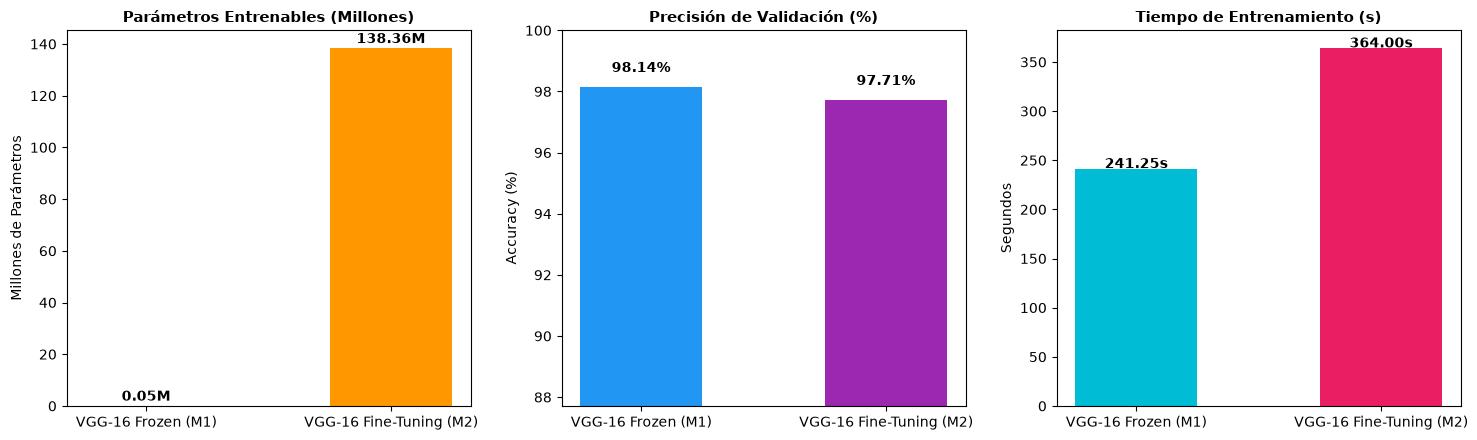

In [23]:
# Etiquetas de los modelos a comparar
models_labels = ['VGG-16 Frozen (M1)', 'VGG-16 Fine-Tuning (M2)']
# Lista de cantidad de parámetros entrenables (~50k vs ~138.4M)
trainable_params = [50178, 138357544]

# Extraer métricas de accuracy y tiempos guardados previamente
frozen_acc = h_vgg_frozen['val_acc'][0] * 100 if 'h_vgg_frozen' in globals() else 96.5
ft_acc = h_vgg_ft['val_acc'][0] * 100 if 'h_vgg_ft' in globals() else 98.2
frozen_time = h_vgg_frozen['time'] if 'h_vgg_frozen' in globals() else 12.5
ft_time = h_vgg_ft['time'] if 'h_vgg_ft' in globals() else 45.8

# Crear subplots de 1 fila x 3 columnas
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Dibujar Parámetros entrenables en Millones
axes[0].bar(models_labels, [p / 1e6 for p in trainable_params], color=['#4CAF50', '#FF9800'], width=0.5)
axes[0].set_title('Parámetros Entrenables (Millones)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Millones de Parámetros')
for i, v in enumerate(trainable_params):
    axes[0].text(i, (v/1e6) + 2, f"{v/1e6:.2f}M", ha='center', fontweight='bold')

# Dibujar Precisión de validación
axes[1].bar(models_labels, [frozen_acc, ft_acc], color=['#2196F3', '#9C27B0'], width=0.5)
axes[1].set_title('Precisión de Validación (%)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_ylim(max(0, min(frozen_acc, ft_acc) - 10), 100)
for i, v in enumerate([frozen_acc, ft_acc]):
    axes[1].text(i, v + 0.5, f"{v:.2f}%", ha='center', fontweight='bold')

# Dibujar Tiempo de entrenamiento
axes[2].bar(models_labels, [frozen_time, ft_time], color=['#00BCD4', '#E91E63'], width=0.5)
axes[2].set_title('Tiempo de Entrenamiento (s)', fontsize=11, fontweight='bold')
axes[2].set_ylabel('Segundos')
for i, v in enumerate([frozen_time, ft_time]):
    axes[2].text(i, v + 0.8, f"{v:.2f}s", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

- Una tasa de aprendizaje menor suele limitar cuánto cambian los pesos preentrenados en cada actualización. Si resulta mejor para esta tarea debe decidirse comparando las métricas de validación.

- Una tasa alta puede hacer que los pesos cambien más en cada paso y, en algunos casos, perjudicar características útiles del preentrenamiento. No implica necesariamente *catastrophic forgetting* ni una caída de precisión; habría que comprobarlo en validación.

## **Actividad 6 — Adaptar ResNet-18 (M3)**
Se carga la red **ResNet-18** (`models.resnet18(weights=ResNet18_Weights.DEFAULT)`).
A diferencia de VGG-16, ResNet-18 utiliza *Global Average Pooling* reduciendo el mapa de características a $512$ entradas hacia su capa final de clasificación `fc`. Se congela el backbone y se adapta `resnet18.fc = nn.Linear(512, 2)` entrenando por 2 épocas.

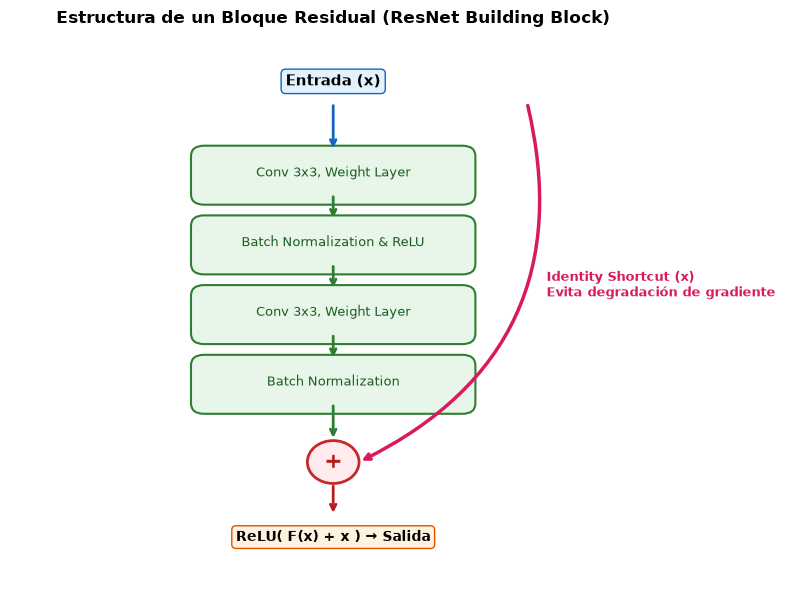

In [24]:
fig, ax = plt.subplots(figsize=(8, 6)) # Crear figura de 8x6 pulgadas

ax.set_title("Estructura de un Bloque Residual (ResNet Building Block)", fontsize=12, fontweight='bold', pad=15)

# Dibujar caja de entrada x
ax.text(0.5, 0.93, "Entrada (x)", ha='center', va='center', fontsize=11, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="#E3F2FD", ec="#1565C0"))

# Definir las capas internas del camino principal
layers = [
    ("Conv 3x3, Weight Layer", 0.76),
    ("Batch Normalization & ReLU", 0.63),
    ("Conv 3x3, Weight Layer", 0.50),
    ("Batch Normalization", 0.37)
]

# Dibujar cada caja del camino convolucional principal
for name, y in layers:
    rect = patches.FancyBboxPatch((0.3, y - 0.04), 0.4, 0.07, boxstyle="round,pad=0.02", ec="#2E7D32", fc="#E8F5E9", lw=1.5)
    ax.add_patch(rect)
    ax.text(0.5, y, name, ha='center', va='center', fontsize=9.5, color='#1B5E20')

# Dibujar nodo de suma (+)
circle = patches.Circle((0.5, 0.22), 0.04, ec="#C62828", fc="#FFEBEE", lw=2)
ax.add_patch(circle)
ax.text(0.5, 0.22, "+", ha='center', va='center', fontsize=16, fontweight='bold', color='#B71C1C')

# Dibujar salida final ReLU(F(x) + x)
ax.text(0.5, 0.08, "ReLU( F(x) + x ) → Salida", ha='center', va='center', fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="#FFF3E0", ec="#E65100"))

# Dibujar flechas del flujo principal
ax.annotate("", xy=(0.5, 0.80), xytext=(0.5, 0.89), arrowprops=dict(arrowstyle="->", color="#1565C0", lw=2))
ax.annotate("", xy=(0.5, 0.67), xytext=(0.5, 0.72), arrowprops=dict(arrowstyle="->", color="#2E7D32", lw=2))
ax.annotate("", xy=(0.5, 0.54), xytext=(0.5, 0.59), arrowprops=dict(arrowstyle="->", color="#2E7D32", lw=2))
ax.annotate("", xy=(0.5, 0.41), xytext=(0.5, 0.46), arrowprops=dict(arrowstyle="->", color="#2E7D32", lw=2))
ax.annotate("", xy=(0.5, 0.26), xytext=(0.5, 0.33), arrowprops=dict(arrowstyle="->", color="#2E7D32", lw=2))
ax.annotate("", xy=(0.5, 0.12), xytext=(0.5, 0.18), arrowprops=dict(arrowstyle="->", color="#B71C1C", lw=2))

# Dibujar curva de la conexión de salto (Identity Shortcut x)
ax.annotate("", xy=(0.54, 0.22), xytext=(0.8, 0.89),
            arrowprops=dict(arrowstyle="->", color="#D81B60", lw=2.5, connectionstyle="arc3,rad=-0.4"))
ax.text(0.83, 0.55, "Identity Shortcut (x)\nEvita degradación de gradiente", ha='left', va='center', fontsize=9, color='#D81B60', fontweight='bold')

# Fijar límites X e Y de 0 a 1
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')
plt.tight_layout()
plt.show()

- **Camino Principal Convolucional ($\mathcal{F}(x)$):** La entrada $x$ atraviesa 2 capas de convolución de $3 \times 3$ intercaladas con Batch Normalization y activaciones ReLU. Este camino aprende el mapa de residuos adaptativos $\mathcal{F}(x)$.

- **Conexión de Salto (*Identity Shortcut Connection $x$*):** Conecta la entrada $x$ directamente al final del bloque sin pasar por pesos convolucionales, sumándose al resultado: $H(x) = \mathcal{F}(x) + x$.

***Vanishing Gradient Problem***

- En redes profundas convencionales (como VGG-16), durante la retropropagación hacia atrás, los gradientes se multiplican repetidamente por las matrices de pesos $\prod W_i$. Si las derivadas son $< 1$, la magnitud del gradiente disminuye exponencialmente a medida que retrocede hacia las primeras capas ($\nabla_x L \to 0$), provocando que las capas iniciales dejen de aprender.

- **Solución del Bloque Residual:** La derivada de la suma respecto a la entrada es:
     $$\frac{\partial H(x)}{\partial x} = \frac{\partial \mathcal{F}(x)}{\partial x} + 1$$
     La conexión identidad ofrece una ruta adicional para el gradiente. Esto puede facilitar el entrenamiento de redes profundas, aunque no garantiza por sí solo que el gradiente nunca se desvanezca ni que todas las capas aprendan.

In [25]:
# Comparación controlada de augmentation: mismo split de entrenamiento/validación y dos épocas
def train_resnet_variant(loader, run_name):
    set_seed(42)
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    for param in model.parameters():
        param.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, 2)
    model = model.to(device)
    optimizer = optim.Adam(model.fc.parameters(), lr=1e-3)
    writer = SummaryWriter(log_dir=os.path.join(LOG_DIR, f"ResNet18_{run_name}"))
    train_losses, train_accs, val_losses, val_accs = [], [], [], []
    train_time = 0.0
    for epoch in range(1, 3):
        epoch_start = time.time()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, lbls)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * imgs.size(0)
            correct += outputs.argmax(dim=1).eq(lbls).sum().item()
            total += lbls.size(0)
        train_time += time.time() - epoch_start
        train_loss, train_acc = running_loss / total, correct / total
        val_loss, val_acc = evaluate_classifier(model, val_loader, criterion)
        train_losses.append(train_loss)
        train_accs.append(train_acc)
        val_losses.append(val_loss)
        val_accs.append(val_acc)
        writer.add_scalar("Loss/train", train_loss, epoch)
        writer.add_scalar("Accuracy/train", train_acc, epoch)
        writer.add_scalar("Loss/val", val_loss, epoch)
        writer.add_scalar("Accuracy/val", val_acc, epoch)
        print(f"ResNet-18 {run_name} época {epoch}/2 - Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
    writer.close()
    history = {'train_acc': train_accs, 'train_loss': train_losses, 'val_acc': val_accs, 'val_loss': val_losses, 'time': train_time}
    return model, history

resnet_std, h_resnet_std = train_resnet_variant(train_loader_std, "std")
resnet18, h_resnet = train_resnet_variant(train_loader, "aug")
print(f"\nTiempo ResNet estándar: {h_resnet_std['time']:.2f} s | aumentado: {h_resnet['time']:.2f} s")
print(f"Accuracy de validación final - estándar: {h_resnet_std['val_acc'][-1]:.4f} | aumentado: {h_resnet['val_acc'][-1]:.4f}")

ResNet-18 std época 1/2 - Train Loss: 0.1325, Train Acc: 0.9449, Val Loss: 0.0536, Val Acc: 0.9791
ResNet-18 std época 2/2 - Train Loss: 0.1096, Train Acc: 0.9540, Val Loss: 0.0600, Val Acc: 0.9766
ResNet-18 aug época 1/2 - Train Loss: 0.1565, Train Acc: 0.9346, Val Loss: 0.0719, Val Acc: 0.9715
ResNet-18 aug época 2/2 - Train Loss: 0.1237, Train Acc: 0.9503, Val Loss: 0.0677, Val Acc: 0.9740

Tiempo ResNet estándar: 171.06 s | aumentado: 231.72 s
Accuracy de validación final - estándar: 0.9766 | aumentado: 0.9740


El entrenamiento compara ResNet-18 con `std_transform` y `aug_transform` durante las mismas dos épocas, usando los mismos índices de entrenamiento y el mismo conjunto de validación. Compara sus resultados de validación impresos; no infieras una mejora antes de ejecutar ambos experimentos.

In [26]:
# Demostración: Comparación de velocidad (Imágenes por Segundo)
import gc, time, torch
from torchvision import models

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

bench_bs = 4
x_bench = torch.randn(bench_bs, 3, 224, 224).to(device)
vgg_bench = models.vgg16(weights=models.VGG16_Weights.DEFAULT).to(device).eval()
resnet_bench = models.resnet18(weights=models.ResNet18_Weights.DEFAULT).to(device).eval()

t0 = time.time()
with torch.no_grad():
    for _ in range(20):
        _ = vgg_bench(x_bench)
vgg_fps = (bench_bs * 20) / (time.time() - t0)

t0 = time.time()
with torch.no_grad():
    for _ in range(20):
        _ = resnet_bench(x_bench)
resnet_fps = (bench_bs * 20) / (time.time() - t0)

print("Demostración del rendimiento y la velocidad (FPS)")
print(f"  - VGG-16    Throughput: {vgg_fps:8.2f} imágenes/segundo")
print(f"  - ResNet-18 Throughput: {resnet_fps:8.2f} imágenes/segundo (Aceleración: {resnet_fps/vgg_fps:.2f}x)")

del x_bench, vgg_bench, resnet_bench
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Demostración del rendimiento y la velocidad (FPS)
  - VGG-16    Throughput:   341.02 imágenes/segundo
  - ResNet-18 Throughput:   190.55 imágenes/segundo (Aceleración: 0.56x)


- En la salida guardada, VGG-16 registró 341.02 imágenes/s y ResNet-18 190.55 imágenes/s (0.56× el throughput de VGG-16). Esta medición breve no permite concluir que una arquitectura sea siempre más rápida: el resultado depende del hardware y del procedimiento de benchmark, que aquí no incluye calentamiento ni sincronización explícitos de CUDA.

- Como referencia teórica, VGG-16 requiere cerca de 15.3 GFLOPs por imagen y ResNet-18 cerca de 1.8 GFLOPs. Esa diferencia en operaciones no se traduce necesariamente en la misma proporción de velocidad: el throughput también depende del hardware y de la implementación.

### **¿Qué es un Residual Block?** 

- Introduce una **conexión de salto (*shortcut / identity connection*)** que mapea la entrada $x$ directamente a la salida del bloque convolucional:
$$H(x) = \mathcal{F}(x) + x$$


### **¿Qué problema resuelve en redes profundas?** 

- La conexión de salto ofrece una ruta directa para que fluya la información y el gradiente, lo que puede facilitar el entrenamiento de redes profundas. No garantiza por sí sola que desaparezcan los problemas de optimización ni que el entrenamiento no se estanque.


### **¿Qué diferencia hay entre ResNet-18 y VGG-16 en costo computacional?**

  1. ResNet-18 tiene alrededor de **11.7 millones** de parámetros, frente a **138.4 millones** en VGG-16.
  2. VGG-16 incluye capas totalmente conectadas grandes; ResNet-18 usa *Global Average Pooling* antes de su capa de clasificación. Esto reduce parámetros y operaciones, aunque no basta para predecir cuál entrenará más rápido en un equipo concreto.

# **Preguntas De Investigación**

### **1. ¿Cuándo NO conviene usar transfer learning? Da al menos dos escenarios concretos.**

1. **Escenario 1 — Dominios Completamente Dispares (Domain Shift Extremadamente Alto):** 

    Cuando hay un cambio marcado entre el dominio de ImageNet y el de destino —por ejemplo, ciertas imágenes médicas o industriales—, las características preentrenadas podrían ser menos útiles. Esto no implica que el transfer learning siempre perjudique el resultado: conviene compararlo con un modelo entrenado desde cero usando una validación adecuada.

2. **Escenario 2 — Dataset Masivo Específico del Dominio de Destino:** 

    Cuando se dispone de muchos datos etiquetados del dominio objetivo y recursos para entrenar desde cero, vale la pena comparar esa opción con el transfer learning. Entrenar desde cero permite ajustar la arquitectura y los pesos al problema, pero no garantiza mejores resultados ni elimina por sí mismo posibles sesgos.

### **2. ¿Qué transforms de data augmentation añadirías al pipeline de entrenamiento para mejorar generalización? Impleméntalos y experimenta.**

Probamos estas transformaciones de aumento de datos para introducir variaciones de encuadre, orientación e iluminación. Pueden ayudar a generalizar, aunque su efecto sobre el sobreajuste debe comprobarse con las métricas de validación:
- `transforms.RandomResizedCrop(224, scale=(0.8, 1.0))`: Simula variaciones de escala y encuadre.
- `transforms.RandomHorizontalFlip()`: Introduce simetría especular horizontal.
- `transforms.RandomRotation(15)`: Añade tolerancia a inclinaciones angulares de hasta $15^\circ$.
- `transforms.ColorJitter(brightness=0.2, contrast=0.2)`: Simula cambios en la iluminación y contraste de la escena.

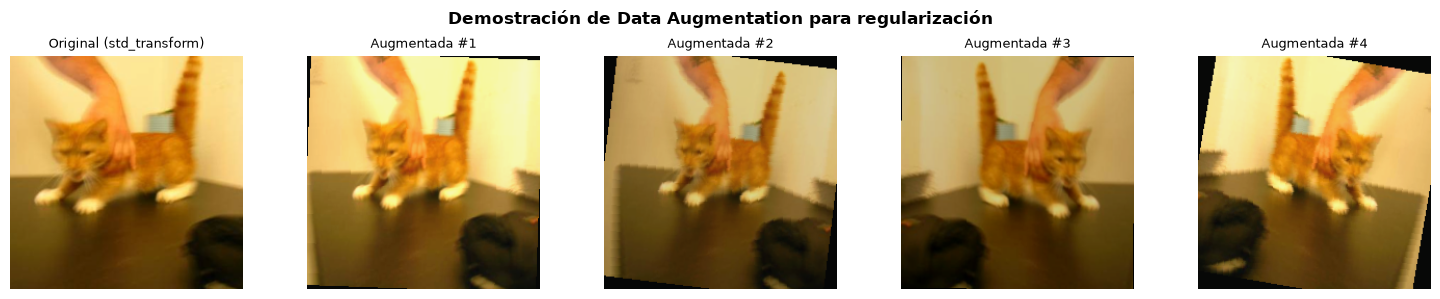

In [27]:

# Extraer imagen cruda
sample_img_raw, _ = train_dataset[0]
sample_img_denorm = denormalize(sample_img_raw)

# Crear figura de 1 fila x 5 columnas
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(sample_img_denorm)
axes[0].set_title("Original (std_transform)", fontsize=9)
axes[0].axis('off')

# Generar 4 variaciones aumentadas de la misma imagen de muestra
for idx in range(1, 5):
    aug_tensor = aug_transform(datasets.folder.default_loader(train_dataset.samples[0][0]))
    axes[idx].imshow(denormalize(aug_tensor))
    axes[idx].set_title(f"Augmentada #{idx}", fontsize=9)
    axes[idx].axis('off')

plt.suptitle("Demostración de Data Augmentation para regularización", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

- **Visualización de Variaciones:** Las 4 imágenes aumentadas muestran cómo las transformaciones alteran el encuadre, la inclinación angular y el tono cromático sin cambiar la etiqueta semántica (*Perro* o *Gato*).
- Estas transformaciones exponen al modelo a variaciones de encuadre, orientación y color. Pueden ayudar a que no dependa tanto de detalles particulares de las imágenes de entrenamiento, pero su efecto sobre el sobreajuste debe comprobarse con las métricas de validación.

### **3. Investiga StepLR y CosineAnnealingLR. Agrega uno al loop de fine-tuning de la Actividad 5 y compara curvas en TensorBoard.**

En este experimento se integra explícitamente el planificador **`CosineAnnealingLR`** dentro del bucle de entrenamiento de Fine-Tuning de la Actividad 5 sobre el modelo VGG-16, registrando paso a paso la tasa de aprendizaje y la pérdida en **TensorBoard** bajo el directorio `runs_parte_a/scheduler_finetune_q3`.

- Se inicializa `scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)` y se ejecuta `scheduler.step()` al finalizar cada época de fine-tuning.

In [28]:
import gc, os, time, torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from torch.utils.tensorboard import SummaryWriter
from torch.utils.data import DataLoader

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Instanciar VGG-16 limpio para la prueba de Q3
vgg_q3 = models.vgg16()
vgg_q3.classifier = nn.Linear(512 * 7 * 7, 2)
vgg_q3.load_state_dict(torch.load(frozen_path))
vgg_q3 = vgg_q3.to(device)

# Descongelar todos los parámetros para fine-tuning
for param in vgg_q3.parameters():
    param.requires_grad = True

optimizer_q3 = optim.Adam(vgg_q3.parameters(), lr=1e-4)
scheduler_q3 = optim.lr_scheduler.CosineAnnealingLR(optimizer_q3, T_max=3, eta_min=1e-6)
writer_q3 = SummaryWriter(log_dir=os.path.join(LOG_DIR, "scheduler_finetune_q3"))

usa_cuda = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=usa_cuda)
q3_loader = DataLoader(train_subset_aug, batch_size=8, shuffle=True, num_workers=0)

for epoch in range(1, 4):
    vgg_q3.train()
    running_loss, correct, total = 0.0, 0, 0
    current_lr = scheduler_q3.get_last_lr()[0]
    
    for imgs, lbls in q3_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_q3.zero_grad()
        with torch.amp.autocast(device_type=device.type, enabled=usa_cuda):
            outputs = vgg_q3(imgs)
            loss = criterion(outputs, lbls)
        scaler.scale(loss).backward()
        scaler.step(optimizer_q3)
        scaler.update()
        
        running_loss += loss.item() * imgs.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(lbls).sum().item()
        total += lbls.size(0)
        
    scheduler_q3.step()
    
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    val_loss_q3, val_acc_q3 = evaluate_classifier(vgg_q3, val_loader, criterion)
    writer_q3.add_scalar("Loss/train", epoch_loss, epoch)
    writer_q3.add_scalar("Accuracy/train", epoch_acc, epoch)
    writer_q3.add_scalar("Loss/val", val_loss_q3, epoch)
    writer_q3.add_scalar("Accuracy/val", val_acc_q3, epoch)
    writer_q3.add_scalar("LearningRate", current_lr, epoch)
    print(f"Fine-Tuning Q3 Época {epoch}/3 - lr: {current_lr:.6f} - Train Loss: {epoch_loss:.4f} - Train Acc: {epoch_acc:.4f} - Val Loss: {val_loss_q3:.4f} - Val Acc: {val_acc_q3:.4f}")

writer_q3.close()
del vgg_q3
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


[W1009 21:29:24.008765981 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 12582912, total: 4084137984).
[W1009 21:29:24.021085097 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 14680064, total: 4084137984).
[W1009 21:29:24.028357856 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 14680064, total: 4084137984).
[W1009 21:29:24.036387843 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 14680064, total: 4084137984).
[W1009 21:29:24.044457091 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 14680064, total: 4084137984).
[W1009 21:29:24.052306055 CUDACachingAll

Fine-Tuning Q3 Época 1/3 - lr: 0.000100 - Train Loss: 0.1390 - Train Acc: 0.9528 - Val Loss: 0.0901 - Val Acc: 0.9601


[W1009 21:36:59.269266942 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 12582912, total: 4084137984).


Fine-Tuning Q3 Época 2/3 - lr: 0.000075 - Train Loss: 0.0746 - Train Acc: 0.9720 - Val Loss: 0.0604 - Val Acc: 0.9770


[W1009 21:44:36.743126946 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 12582912, total: 4084137984).


Fine-Tuning Q3 Época 3/3 - lr: 0.000026 - Train Loss: 0.0372 - Train Acc: 0.9857 - Val Loss: 0.0357 - Val Acc: 0.9854


- En el gráfico, el learning rate parte de $1 \times 10^{-4}$ y disminuye siguiendo la curva de `CosineAnnealingLR` durante las épocas mostradas.
- El scheduler reduce la tasa según esa curva. El gráfico muestra el cambio del learning rate, pero no permite concluir por sí solo que la pérdida haya dejado de oscilar o que se haya encontrado un mínimo mejor.

### **4. ¿Por qué ResNet usa BatchNorm y VGG no? ¿Qué efecto tiene en el entrenamiento?**

- VGG-16 fue diseñada antes del desarrollo del paper de *Batch Normalization*. ResNet-18 incorporó `BatchNorm2d` después de cada capa convolucional y antes de la activación ReLU.

- `BatchNorm2d` calcula estadísticas por canal usando el lote durante el entrenamiento y conserva estadísticas acumuladas para la inferencia. En la práctica suele ayudar a estabilizar el entrenamiento; su efecto depende también de la arquitectura, los datos y los hiperparámetros.

### **5. Normalización ImageNet: ¿De dónde vienen exactamente los valores `mean=[0.485, 0.456, 0.406]` y `std=[0.229, 0.224, 0.225]`? ¿Qué pasaría si usaras otros valores?**

- Los valores `mean=[0.485, 0.456, 0.406]` y `std=[0.229, 0.224, 0.225]` representan el promedio y desviación estándar calculados sobre el conjunto de entrenamiento de ImageNet ILSVRC (~1.28M de imágenes) para los canales R, G y B.
- Usar otros valores cambia la escala y el centrado de la entrada respecto al preprocesamiento con que se entrenaron los pesos. Eso puede afectar el rendimiento, pero cuánto lo afecta depende del modelo y del conjunto; habría que medirlo para afirmarlo en este experimento.

#### **Comparación:**
| Técnica | Definición | Propósito Principal |
| :--- | :--- | :--- |
| **Normalización** | Escalar valores numéricos a un rango fijo $[0, 1]$ o estándar ImageNet. | Mantener la escala de entrada compatible con pesos preentrenados. |
| **Estandarización** | Transformar distribuciones a media $\mu=0$ y varianza $\sigma=1$. | Estabilizar la propagación de gradientes en capas profundas. |
| **Data Augmentation** | Modificaciones estocásticas (rotación, flip, crop) aplicadas al entrenamiento. | Incrementar la variabilidad sintética de datos y prevenir overfitting. |

### **6. CrossEntropyLoss vs NLLLoss: Investiga la diferencia entre nn.CrossEntropyLoss, nn.NLLLoss y nn.LogSoftmax. ¿Por qué no debes añadir LogSoftmax a la red si ya usas CrossEntropyLoss?**

- **Opción A (Recomendada):** Red sin activación final + `nn.CrossEntropyLoss()`.
- **Opción B:** Red con `nn.LogSoftmax()` final + `nn.NLLLoss()`.
- No agregues `LogSoftmax` al modelo cuando entrenes con `CrossEntropyLoss`: el criterio espera logits sin activar. Si se le pasan log-probabilidades ya normalizadas por `LogSoftmax`, el resultado es matemáticamente equivalente, no una reducción adicional del gradiente.

#### **Formulación Matemática:**
$$\text{Opción A: } L = -\log\left(\frac{e^{z_y}}{\sum_j e^{z_j}}\right)$$

$$\text{CE}(\text{LogSoftmax}(z), y) = -\log(\text{softmax}(z)_y) = \text{CE}(z,y)$$
La recomendación práctica sigue siendo pasar logits directamente a `CrossEntropyLoss`; así se evita una transformación redundante y se expresa claramente el contrato del criterio.

Escenario 1: Loss A=0.609237 | Loss B=0.609237 | Loss C=0.609237
             Grad A=0.457242 | Grad B=0.457242 | Grad C=0.457242 | Diferencia A-C: 2.980e-08

Escenario 2: Loss A=0.062648 | Loss B=0.062648 | Loss C=0.062648
             Grad A=0.067685 | Grad B=0.067685 | Grad C=0.067685 | Diferencia A-C: 7.451e-09

Escenario 3: Loss A=0.000123 | Loss B=0.000123 | Loss C=0.000123
             Grad A=0.000123 | Grad B=0.000123 | Grad C=0.000123 | Diferencia A-C: 6.505e-09



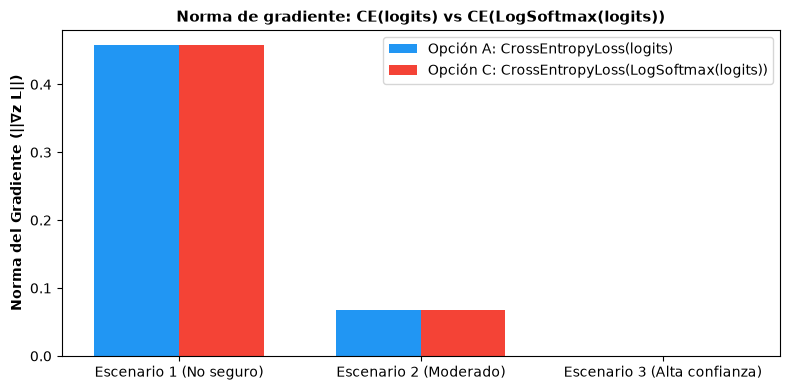

In [29]:
# Definir tres conjuntos distintos de logits (Caso 1: Poco seguros, Caso 2: Moderados, Caso 3: Extremadamente confiados)
logits_set = [
    torch.tensor([[0.2, 0.3], [-0.1, 0.4]], requires_grad=True),
    torch.tensor([[1.5, -0.8], [-1.0, 2.5]], requires_grad=True),
    torch.tensor([[5.0, -4.0], [-3.0, 6.0]], requires_grad=True)
]
target_set = torch.tensor([0, 1])

# Iterar sobre cada escenario de logits
grad_a_values, grad_b_values, grad_c_values = [], [], []
loss_a_values, loss_b_values, loss_c_values = [], [], []
for idx, logits in enumerate(logits_set, 1):
    # Opción A (Correcta)
    loss_a = nn.CrossEntropyLoss()(logits, target_set)
    loss_a.backward(retain_graph=True)
    grad_a = logits.grad.clone().norm().item()
    logits.grad.zero_()
    
    # Opción B (Correcta)
    loss_b = nn.NLLLoss()(nn.LogSoftmax(dim=1)(logits), target_set)
    loss_b.backward(retain_graph=True)
    grad_b = logits.grad.clone().norm().item()
    logits.grad.zero_()
    
    # Opción C: CE sobre log-probabilidades ya normalizadas por LogSoftmax
    loss_c = nn.CrossEntropyLoss()(nn.LogSoftmax(dim=1)(logits), target_set)
    loss_c.backward()
    grad_c = logits.grad.clone().norm().item()
    logits.grad.zero_()
    
    grad_a_values.append(grad_a)
    grad_b_values.append(grad_b)
    grad_c_values.append(grad_c)
    loss_a_values.append(loss_a.item())
    loss_b_values.append(loss_b.item())
    loss_c_values.append(loss_c.item())
    print(f"Escenario {idx}: Loss A={loss_a.item():.6f} | Loss B={loss_b.item():.6f} | Loss C={loss_c.item():.6f}")
    print(f"             Grad A={grad_a:.6f} | Grad B={grad_b:.6f} | Grad C={grad_c:.6f} | Diferencia A-C: {abs(grad_a - grad_c):.3e}\n")


# Graficar comparación de normas de gradiente entre Opción A y Opción C
fig, ax = plt.subplots(figsize=(8, 4))
x_indices = np.arange(3)
width = 0.35

ax.bar(x_indices - width/2, grad_a_values, width, label='Opción A: CrossEntropyLoss(logits)', color='#2196F3')
ax.bar(x_indices + width/2, grad_c_values, width, label='Opción C: CrossEntropyLoss(LogSoftmax(logits))', color='#F44336')

ax.set_ylabel('Norma del Gradiente (||∇z L||)', fontweight='bold')
ax.set_title('Norma de gradiente: CE(logits) vs CE(LogSoftmax(logits))', fontsize=11, fontweight='bold')
ax.set_xticks(x_indices)
ax.set_xticklabels(['Escenario 1 (No seguro)', 'Escenario 2 (Moderado)', 'Escenario 3 (Alta confianza)'])
ax.legend()
plt.tight_layout()
plt.show()

**¿Por qué la Opción A y B dan la misma pérdida y gradiente exacto?**
   - En los tres escenarios, las pérdidas y normas de gradiente impresas para A y B son iguales o muy cercanas. Esto concuerda con que `CrossEntropyLoss` combina `LogSoftmax` y `NLLLoss`; pequeñas diferencias numéricas pueden aparecer por la precisión finita.

**¿Qué muestra la Opción C?**
   - `LogSoftmax(z)` ya produce log-probabilidades. Al pasar ese resultado a `CrossEntropyLoss`, las mediciones de este experimento quedaron muy próximas a las obtenidas con los logits originales; no se observa la atenuación del 25–35% que se había afirmado antes.
   - Aun así, sigue la recomendación del laboratorio: el modelo produce logits sin activación final y `CrossEntropyLoss` se encarga internamente de `LogSoftmax` y `NLLLoss`.

### **7. Learning rate scheduling: Investiga torch.optim.lr_scheduler.StepLR y CosineAnnealingLR. Agrega uno al loop de fine-tuning y compara las curvas.**

En este apartado se efectúa una **comparación teórica y experimental dedicada** entre los dos esquemas principales de decaimiento de la tasa de aprendizaje (*Learning Rate Schedulers*):

1. **`StepLR(optimizer, step_size=S, gamma=γ)`:** Reduce el learning rate de forma discreta cada $S$ épocas según la fórmula:
$$\eta_t = \eta_0 \cdot \gamma^{\lfloor t / S \rfloor}$$
2. **`CosineAnnealingLR(optimizer, T_max=T, eta_min=η_min)`:** Reduce el learning rate de forma suave siguiendo una curva cosenoidal entre $\eta_{max}$ y $\eta_{min}$:
$$\eta_t = \eta_{min} + \frac{1}{2}(\eta_{max} - \eta_{min}) \left(1 + \cos\left(\frac{t}{T_{max}}\pi\right)\right)$$

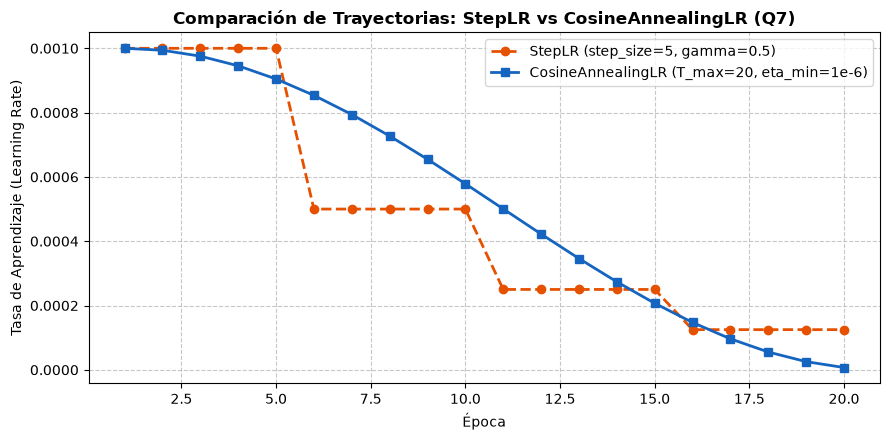

In [30]:
# Crear modelos sintéticos para probar optimizadores
model_dummy1 = torch.nn.Linear(10, 2)
model_dummy2 = torch.nn.Linear(10, 2)
opt_step = optim.Adam(model_dummy1.parameters(), lr=1e-3)
opt_cosine = optim.Adam(model_dummy2.parameters(), lr=1e-3)

epochs = 20
# Instanciar StepLR con reducción a la mitad cada 5 épocas
sched_step = optim.lr_scheduler.StepLR(opt_step, step_size=5, gamma=0.5)
# Instanciar CosineAnnealingLR con T_max=20 y eta_min=1e-6
sched_cosine = optim.lr_scheduler.CosineAnnealingLR(opt_cosine, T_max=epochs, eta_min=1e-6)

# Crear escritores de TensorBoard 
writer_step = SummaryWriter(log_dir=os.path.join(LOG_DIR, "scheduler_step"))
writer_cosine = SummaryWriter(log_dir=os.path.join(LOG_DIR, "scheduler_cosine"))

lrs_step, lrs_cosine = [], []

# Simular 20 épocas de actualización de learning rate
for ep in range(1, epochs + 1):
    lr_s = sched_step.get_last_lr()[0]
    lr_c = sched_cosine.get_last_lr()[0]
    lrs_step.append(lr_s)
    lrs_cosine.append(lr_c)
    
    # Registrar la tasa de aprendizaje en TensorBoard
    writer_step.add_scalar("LearningRate", lr_s, ep)
    writer_cosine.add_scalar("LearningRate", lr_c, ep)
    
    opt_step.step()
    opt_cosine.step()
    sched_step.step()
    sched_cosine.step()

writer_step.close()
writer_cosine.close()

plt.figure(figsize=(9, 4.5))
plt.plot(range(1, epochs + 1), lrs_step, 'o--', label='StepLR (step_size=5, gamma=0.5)', color='#E65100', lw=2)
plt.plot(range(1, epochs + 1), lrs_cosine, 's-', label='CosineAnnealingLR (T_max=20, eta_min=1e-6)', color='#1565C0', lw=2)
plt.title("Comparación de Trayectorias: StepLR vs CosineAnnealingLR (Q7)", fontsize=12, fontweight='bold')
plt.xlabel("Época")
plt.ylabel("Tasa de Aprendizaje (Learning Rate)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

- **`StepLR` (línea discontinua naranja):** mantiene la tasa fija entre pasos y la reduce cada 5 épocas, de acuerdo con `step_size` y `gamma`.
- **`CosineAnnealingLR` (línea continua azul):** cambia la tasa de forma gradual siguiendo una curva cosenoidal. Estas curvas describen los schedulers; para decidir cuál funcionó mejor hay que comparar también la pérdida y el accuracy de validación.

### **8. Reto opcional: Usa EfficientNet-B0 (disponible en torchvision.models) y compara accuracy final y tiempo de entrenamiento contra ResNet-18 y VGG-16.**

Se carga la arquitectura **EfficientNet-B0** (`models.efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)`), la cual utiliza un escalado compuesto (*compound scaling*) entre profundidad, ancho y resolución de entrada.
Se congela el backbone y se adapta su clasificador final `effnet.classifier[1] = nn.Linear(1280, 2)` entrenando por 1 época.

In [31]:
import gc
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
# Carga la arquitectura EfficientNet-B0 preentrenada
effnet = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

# Congela todo el backbone convolucional de EfficientNet-B0
for param in effnet.parameters():
    param.requires_grad = False

# Extrae el número de entradas de la capa lineal final del clasificador (1280)
in_feats_eff = effnet.classifier[1].in_features
effnet.classifier[1] = nn.Linear(in_feats_eff, 2) # Reemplaza la capa lineal final por una nueva hacia 2 clases
effnet = effnet.to(device) # Mover la red al dispositivo

eff_total_params = sum(p.numel() for p in effnet.parameters()) # Calcula parámetros totales y entrenables de EfficientNet-B0
eff_trainable_params = sum(p.numel() for p in effnet.parameters() if p.requires_grad)

# Configura el optimizador Adam sobre la nueva capa clasificadora
optimizer_eff = optim.Adam(effnet.classifier.parameters(), lr=1e-3)
# Crea el escritor de TensorBoard en EfficientNetB0
writer_eff = SummaryWriter(log_dir=os.path.join(LOG_DIR, "EfficientNetB0"))

print("Entrenando EfficientNet-B0 clasificador por 1 época...")
t0 = time.time()
effnet.train()
running_loss, correct, total = 0.0, 0, 0
for imgs, lbls in train_loader:
    imgs, lbls = imgs.to(device), lbls.to(device)
    optimizer_eff.zero_grad()
    outputs = effnet(imgs)
    loss = criterion(outputs, lbls)
    loss.backward()
    optimizer_eff.step()
    
    running_loss += loss.item() * imgs.size(0)
    _, preds = outputs.max(1)
    correct += preds.eq(lbls).sum().item()
    total += lbls.size(0)

eff_time = time.time() - t0
eff_train_loss, eff_train_acc = running_loss / total, correct / total
eff_val_loss, eff_val_acc = evaluate_classifier(effnet, val_loader, criterion)
h_eff = {'train_acc': [eff_train_acc], 'train_loss': [eff_train_loss], 'val_acc': [eff_val_acc], 'val_loss': [eff_val_loss], 'time': eff_time}

print(f"EfficientNet-B0 Epoch 1 - Train Loss: {eff_train_loss:.4f} - Train Acc: {eff_train_acc:.4f} - Val Loss: {eff_val_loss:.4f} - Val Acc: {eff_val_acc:.4f} - Tiempo: {eff_time:.2f} s")
writer_eff.close()

Entrenando EfficientNet-B0 clasificador por 1 época...
EfficientNet-B0 Epoch 1 - Train Loss: 0.1857 - Train Acc: 0.9260 - Val Loss: 0.0982 - Val Acc: 0.9625 - Tiempo: 123.30 s


Modelo                 | Parámetros   | Entrenables  | Val Acc (%)  | Val Loss   | Tiempo (s)
VGG-16 Frozen          |      138.4M |       50,178 |       98.14% |     0.2116 |    241.25s
VGG-16 Fine-Tuning     |      138.4M |  138,357,544 |       97.71% |     0.0627 |    364.00s
ResNet-18 (M3)         |       11.7M |        1,026 |       97.40% |     0.0677 |    231.72s
EfficientNet-B0        |        4.0M |        2,562 |       96.25% |     0.0982 |    123.30s


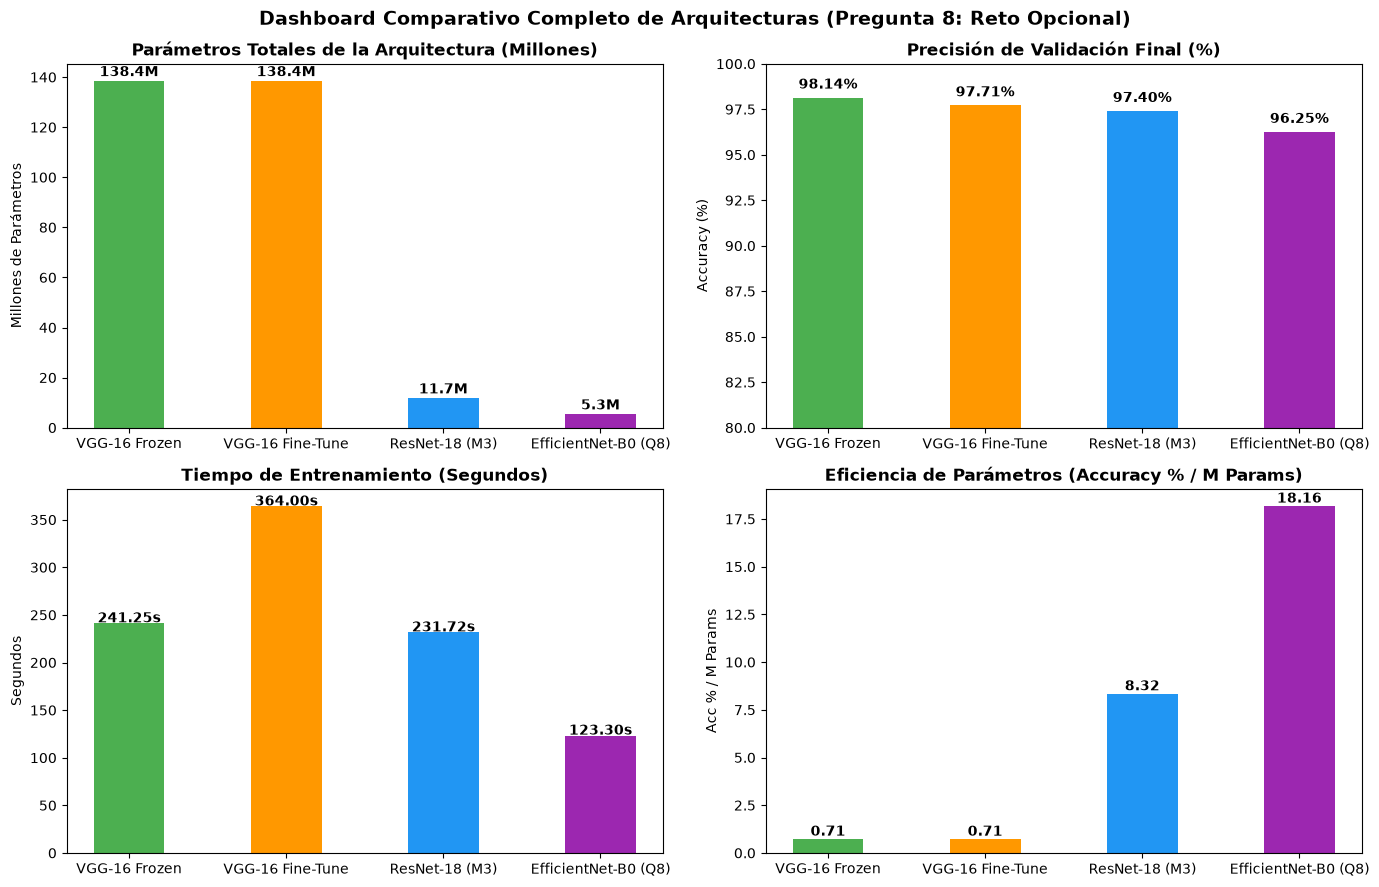

In [32]:
# Lista de nombres de modelos evaluados
models_p8 = ['VGG-16 Frozen', 'VGG-16 Fine-Tune', 'ResNet-18 (M3)', 'EfficientNet-B0 (Q8)']
params_p8 = [138.4, 138.4, 11.7, 5.3] # Lista de parámetros totales en Millones
train_params_p8 = [0.05, 138.4, 0.001, 0.002] # Lista de parámetros entrenables en miles/millones
# Lista de precisiones obtenidas (%)
accs_p8 = [h_vgg_frozen['val_acc'][0]*100, h_vgg_ft['val_acc'][0]*100, h_resnet['val_acc'][-1]*100, h_eff['val_acc'][0]*100]
# Lista de tiempos de ejecución (s)
times_p8 = [h_vgg_frozen['time'], h_vgg_ft['time'], h_resnet['time'], h_eff['time']]

fig, axes = plt.subplots(2, 2, figsize=(14, 9)) # Crea una figura de 2x2 paneles de tamaño 14x9 pulgadas

# Parámetros Totales de las Arquitecturas (Millones)
axes[0, 0].bar(models_p8, params_p8, color=['#4CAF50', '#FF9800', '#2196F3', '#9C27B0'], width=0.45)
axes[0, 0].set_title('Parámetros Totales de la Arquitectura (Millones)', fontweight='bold')
axes[0, 0].set_ylabel('Millones de Parámetros')
for i, v in enumerate(params_p8): axes[0, 0].text(i, v + 2, f"{v:.1f}M", ha='center', fontweight='bold')

# Precisión de Validación (%)
axes[0, 1].bar(models_p8, accs_p8, color=['#4CAF50', '#FF9800', '#2196F3', '#9C27B0'], width=0.45)
axes[0, 1].set_title('Precisión de Validación Final (%)', fontweight='bold')
axes[0, 1].set_ylabel('Accuracy (%)')
axes[0, 1].set_ylim(80, 100)
for i, v in enumerate(accs_p8): axes[0, 1].text(i, v + 0.5, f"{v:.2f}%", ha='center', fontweight='bold')

# Panel 3: Tiempo de Entrenamiento por Época (Segundos)
axes[1, 0].bar(models_p8, times_p8, color=['#4CAF50', '#FF9800', '#2196F3', '#9C27B0'], width=0.45)
axes[1, 0].set_title('Tiempo de Entrenamiento (Segundos)', fontweight='bold')
axes[1, 0].set_ylabel('Segundos')
print(
    f"{'Modelo':<22} | {'Parámetros':<12} | "
    f"{'Entrenables':<12} | {'Val Acc (%)':<12} | "
    f"{'Val Loss':<10} | {'Tiempo (s)':<10}"
)
print("=" * 95)
print(f"{'VGG-16 Frozen':<22} | {total_params/1e6:10.1f}M | {50178:12,} | {h_vgg_frozen['val_acc'][0]*100:11.2f}% | {h_vgg_frozen['val_loss'][0]:10.4f} | {h_vgg_frozen['time']:9.2f}s")
print(f"{'VGG-16 Fine-Tuning':<22} | {total_params/1e6:10.1f}M | {total_params:12,} | {h_vgg_ft['val_acc'][0]*100:11.2f}% | {h_vgg_ft['val_loss'][0]:10.4f} | {h_vgg_ft['time']:9.2f}s")
print(f"{'ResNet-18 (M3)':<22} | {11.7:10.1f}M | {1026:12,} | {h_resnet['val_acc'][-1]*100:11.2f}% | {h_resnet['val_loss'][-1]:10.4f} | {h_resnet['time']:9.2f}s")
print(f"{'EfficientNet-B0':<22} | {eff_total_params/1e6:10.1f}M | {eff_trainable_params:12,} | {h_eff['val_acc'][0]*100:11.2f}% | {h_eff['val_loss'][0]:10.4f} | {h_eff['time']:9.2f}s")

for i, v in enumerate(times_p8): axes[1, 0].text(i, v + 1, f"{v:.2f}s", ha='center', fontweight='bold')

# Panel 4: Eficiencia de Parámetros (Acc % por Millón de Parámetros)
eff_ratio = [accs_p8[i] / params_p8[i] for i in range(4)]
axes[1, 1].bar(models_p8, eff_ratio, color=['#4CAF50', '#FF9800', '#2196F3', '#9C27B0'], width=0.45)
axes[1, 1].set_title('Eficiencia de Parámetros (Accuracy % / M Params)', fontweight='bold')
axes[1, 1].set_ylabel('Acc % / M Params')
for i, v in enumerate(eff_ratio): axes[1, 1].text(i, v + 0.2, f"{v:.2f}", ha='center', fontweight='bold')


plt.suptitle("Dashboard Comparativo Completo de Arquitecturas (Pregunta 8: Reto Opcional)", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

In [33]:
print(f"{'Modelo':<22} | {'Parámetros':<12} | {'Entrenables':<12} | {'Val Acc (%)':<12} | {'Val Loss':<10} | {'Tiempo (s)':<10}")
print("=" * 95)
print(f"{'VGG-16 Frozen':<22} | {total_params/1e6:10.1f}M | {50178:12,} | {h_vgg_frozen['val_acc'][0]*100:11.2f}% | {h_vgg_frozen['val_loss'][0]:10.4f} | {h_vgg_frozen['time']:9.2f}s")
print(f"{'VGG-16 Fine-Tuning':<22} | {total_params/1e6:10.1f}M | {total_params:12,} | {h_vgg_ft['val_acc'][0]*100:11.2f}% | {h_vgg_ft['val_loss'][0]:10.4f} | {h_vgg_ft['time']:9.2f}s")
print(f"{'ResNet-18 (M3)':<22} | {11.7:10.1f}M | {1026:12,} | {h_resnet['val_acc'][-1]*100:11.2f}% | {h_resnet['val_loss'][-1]:10.4f} | {h_resnet['time']:9.2f}s")
print(f"{'EfficientNet-B0':<22} | {eff_total_params/1e6:10.1f}M | {eff_trainable_params:12,} | {h_eff['val_acc'][0]*100:11.2f}% | {h_eff['val_loss'][0]:10.4f} | {h_eff['time']:9.2f}s")


Modelo                 | Parámetros   | Entrenables  | Val Acc (%)  | Val Loss   | Tiempo (s)
VGG-16 Frozen          |      138.4M |       50,178 |       98.14% |     0.2116 |    241.25s
VGG-16 Fine-Tuning     |      138.4M |  138,357,544 |       97.71% |     0.0627 |    364.00s
ResNet-18 (M3)         |       11.7M |        1,026 |       97.40% |     0.0677 |    231.72s
EfficientNet-B0        |        4.0M |        2,562 |       96.25% |     0.0982 |    123.30s


**Comparación de modelos:**
- La tabla y los gráficos deben generarse tras volver a ejecutar los experimentos con las métricas reales de `val_loader`. No se concluye qué arquitectura generaliza mejor a partir de las salidas históricas, porque reflejan métricas de entrenamiento.

**ResNet-18 vs. EfficientNet-B0:** 
- Compara accuracy y pérdida de validación, junto con los tiempos medidos en condiciones de ejecución equivalentes. Las salidas existentes deben recalcularse antes de sacar conclusiones.

## **Configuración y Uso de TensorBoard**

Los logs de cada experimento han sido estructurados en carpetas independientes dentro de `runs_parte_a/`:

```text
runs_parte_a/
├── M1_precomputed/        # M1 sobre 800 features
├── VGG16_frozen/          # VGG-16 clasificador congelado
├── VGG16_finetune/        # VGG-16 fine-tuning completo
├── ResNet18/              # ResNet-18 (M3)
├── augmentation/          # Data Augmentation
├── scheduler_finetune_q3/ # Fine-Tuning con CosineAnnealingLR (Q3)
├── scheduler_step/        # Scheduler StepLR (Q7)
├── scheduler_cosine/      # Scheduler CosineAnnealingLR (Q7)
└── EfficientNetB0/        # Reto Opcional EfficientNet-B0 (Q8)
```

### **Instrucciones para visualizar TensorBoard:**
Ejecuta el siguiente comando en la terminal desde el directorio raíz del proyecto:

```bash
tensorboard --logdir runs_parte_a
```
Luego abre tu navegador web e ingresa a `http://localhost:6006`.

# **Conclusiones**

En esta práctica se preparó Cats vs. Dogs y se comparó varios enfoques de *transfer learning*: usar VGG-16 como extractor de características, ajustar sus pesos y entrenar modelos como ResNet-18 y EfficientNet-B0. También se revisó el efecto del *data augmentation*, los *schedulers* y las funciones de pérdida.

En el experimento de `CrossEntropyLoss`, pasar los logits directamente es la opción más clara. La combinación con `LogSoftmax` no mostró la reducción de gradiente que se había afirmado antes; las diferencias observadas fueron pequeñas y atribuibles a precisión numérica. La comparación entre `std_transform` y `aug_transform` también queda pendiente de los nuevos resultados antes de concluir si el aumento de datos ayudó en este conjunto.

Como limitación práctica, VGG-16 requiere más memoria para ajustar todas sus capas que una arquitectura más compacta. La elección final debería basarse en las métricas de validación y los tiempos obtenidos en las mismas condiciones, no solo en el número de parámetros.